# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge.

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms.

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY).

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS:
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [ ]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [ ]:
#!rm SUSY.csv

In [ ]:
#!gunzip SUSY.csv.gz

In [ ]:
ls -lh

total 4.0K
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root    0 Oct 24 00:24 SUSY-small.csv


The data is provided as a comma separated file.

In [ ]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

head: cannot open 'SUSY.csv' for reading: No such file or directory


## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [ ]:
!ls -lh

total 194M
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data
-rw-r--r-- 1 root root 194M Oct 24 00:23 SUSY-small.csv


We see that we have 5 million datapoints.

In [ ]:
!wc -l SUSY.csv

wc: SUSY.csv: No such file or directory


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [ ]:
!head -500000 SUSY.csv > SUSY-small.csv

head: cannot open 'SUSY.csv' for reading: No such file or directory


In [ ]:
ls -lh

total 4.0K
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root    0 Oct 24 00:24 SUSY-small.csv


In [ ]:
! wc -l SUSY-small.csv

0 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [ ]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [ ]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [ ]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [ ]:
FeatureNames

['M_TR_2',
 'axial_MET',
 'R',
 'MT2',
 'dPhi_r_b',
 'M_Delta_R',
 'M_R',
 'cos_theta_r1',
 'S_R',
 'MET_rel']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [ ]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [ ]:
print(df.shape)
print(df.head())

(500000, 19)
   signal    l_1_pT   l_1_eta   l_1_phi    l_2_pT   l_2_eta   l_2_phi  \
0     0.0  0.972861  0.653855  1.176225  1.157156 -1.739873 -0.874309   
1     1.0  1.667973  0.064191 -1.225171  0.506102 -0.338939  1.672543   
2     1.0  0.444840 -0.134298 -0.709972  0.451719 -1.613871 -0.768661   
3     1.0  0.381256 -0.976145  0.693152  0.448959  0.891753 -0.677328   
4     1.0  1.309996 -0.690089 -0.676259  1.589283 -0.693326  0.622907   

        MET   MET_phi   MET_rel  axial_MET       M_R    M_TR_2         R  \
0  0.567765 -0.175000  0.810061  -0.252552  1.921887  0.889637  0.410772   
1  3.475464 -1.219136  0.012955   3.775174  1.045977  0.568051  0.481928   
2  1.219918  0.504026  1.831248  -0.431385  0.526283  0.941514  1.587535   
3  2.033060  1.533041  3.046260  -1.005285  0.569386  1.015211  1.582217   
4  1.087562 -0.381742  0.589204   1.365479  1.179295  0.968218  0.728563   

        MT2       S_R  M_Delta_R  dPhi_r_b  cos_theta_r1  
0  1.145621  1.932632   0.994464

You can see the data in Jupyter by just evaluating the dataframe:

In [ ]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [ ]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


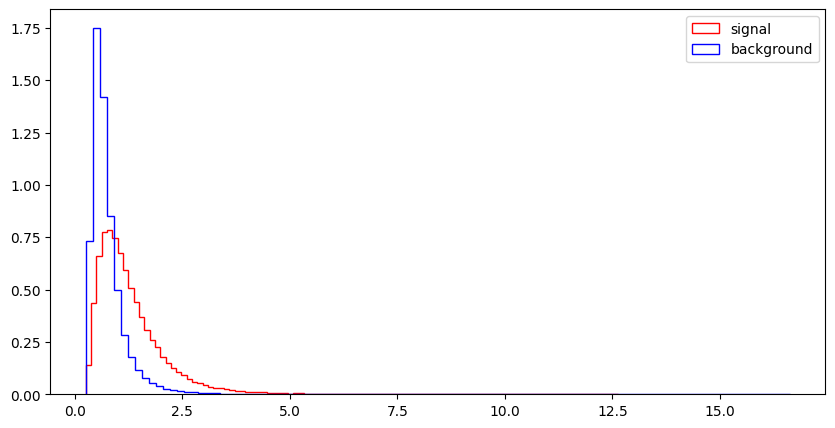

l_1_eta


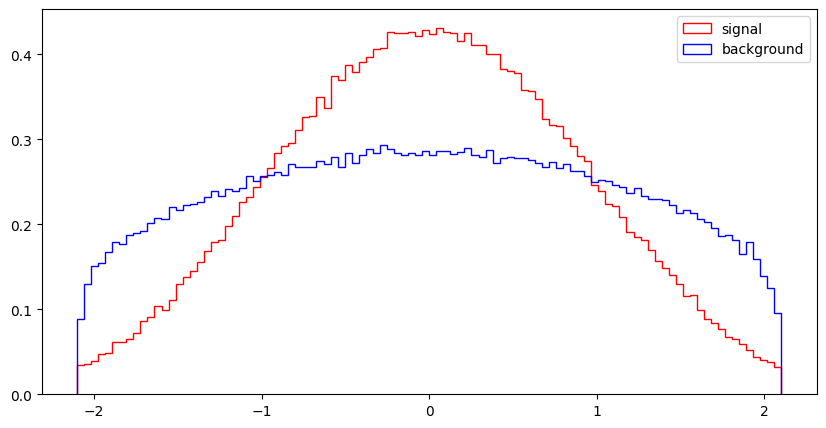

l_1_phi


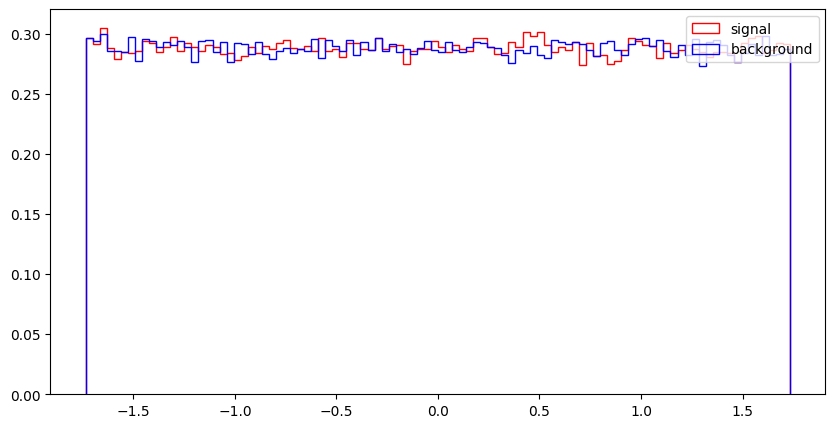

l_2_pT


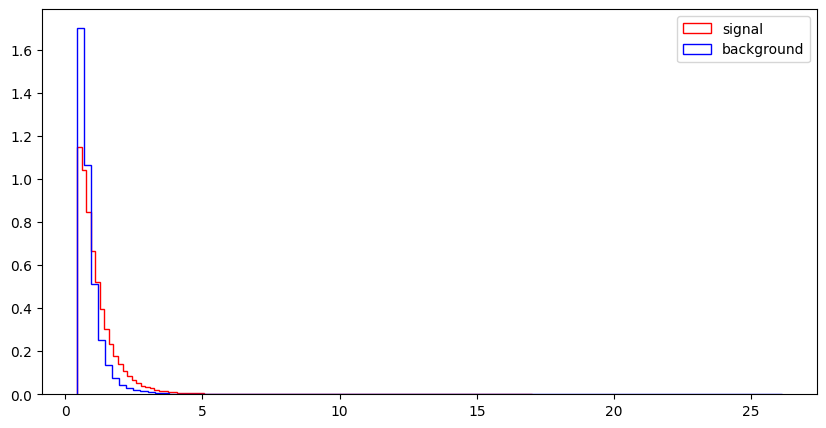

l_2_eta


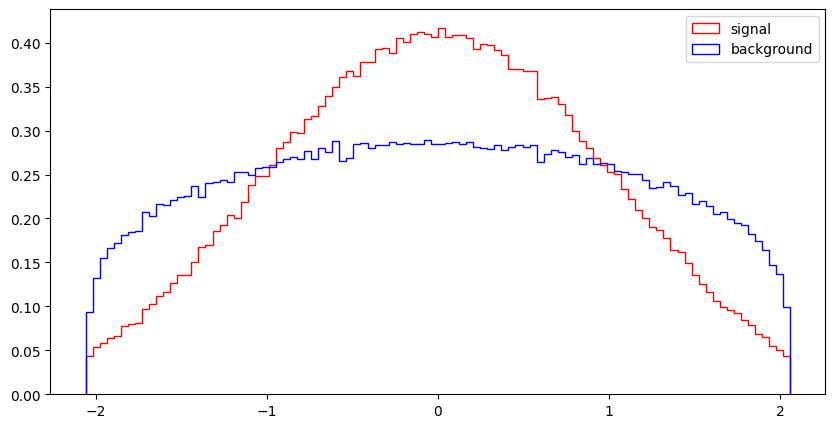

l_2_phi


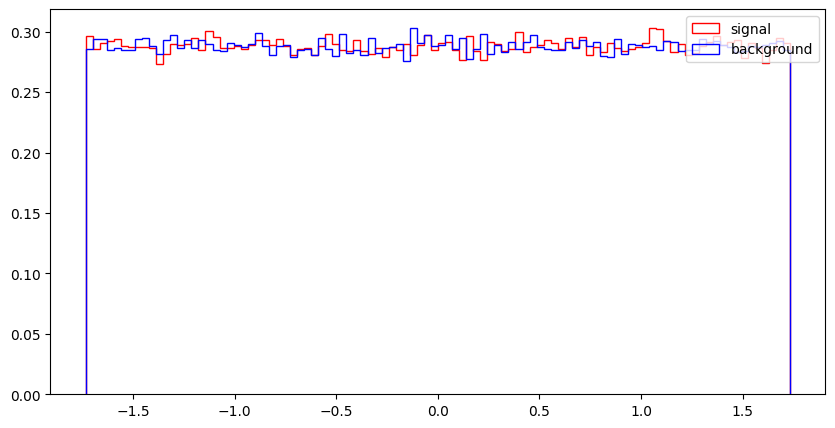

MET


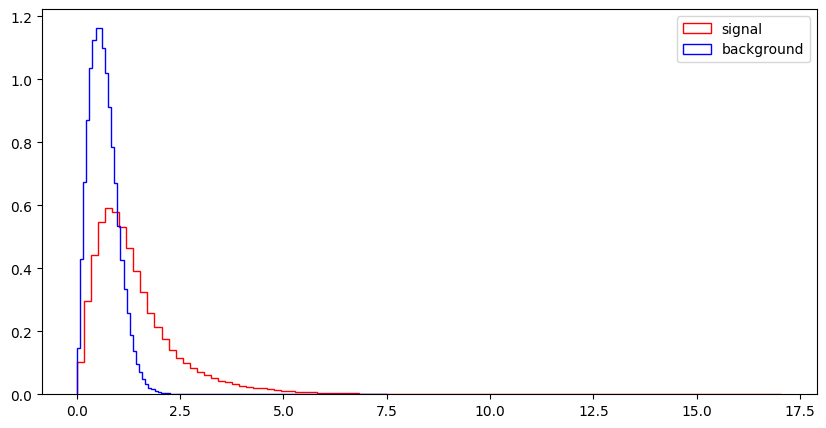

MET_phi


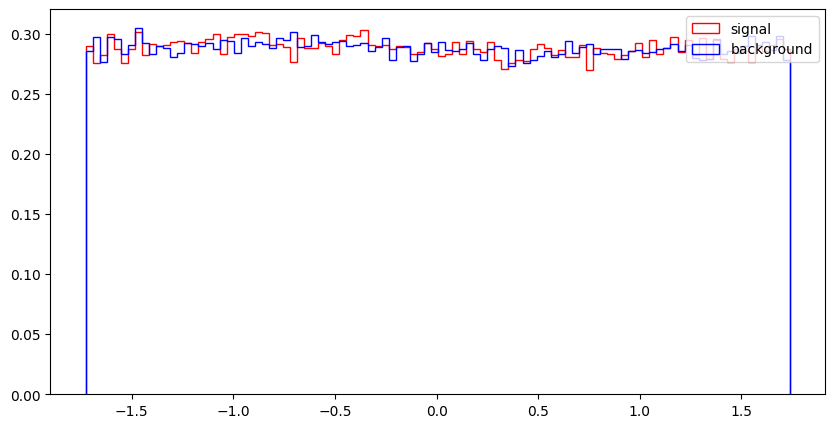

MET_rel


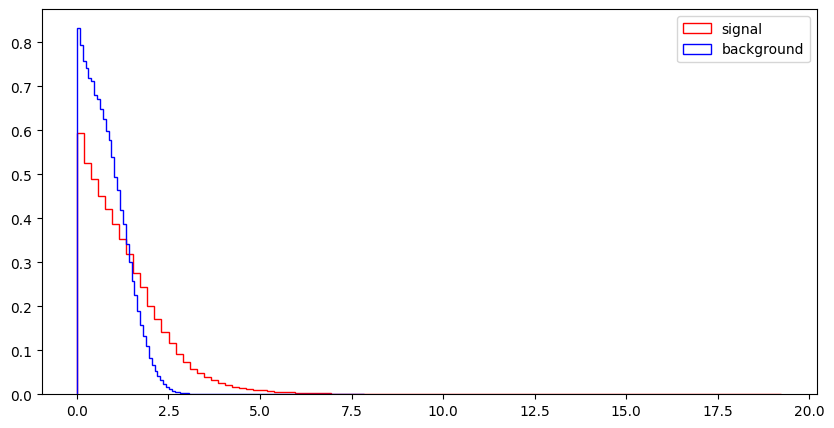

axial_MET


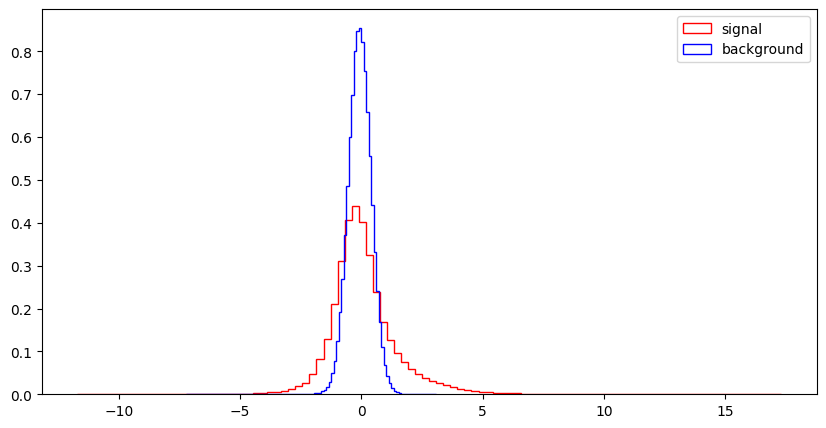

M_R


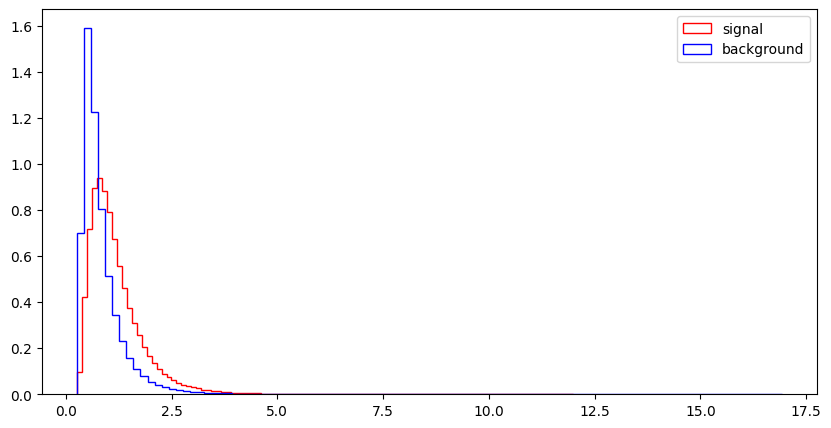

M_TR_2


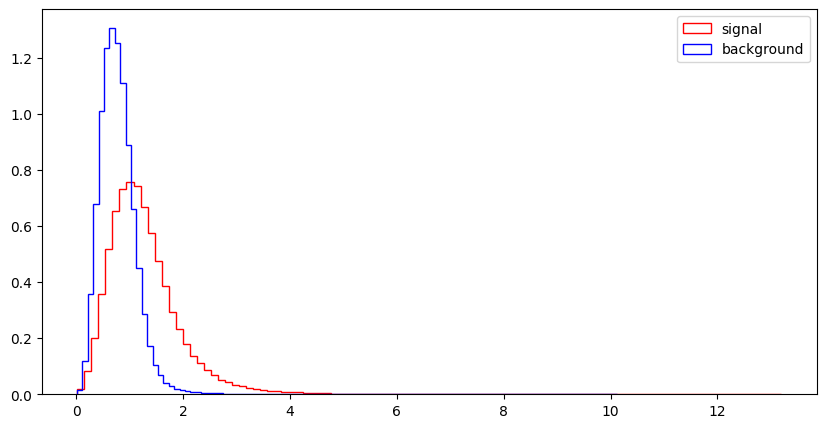

R


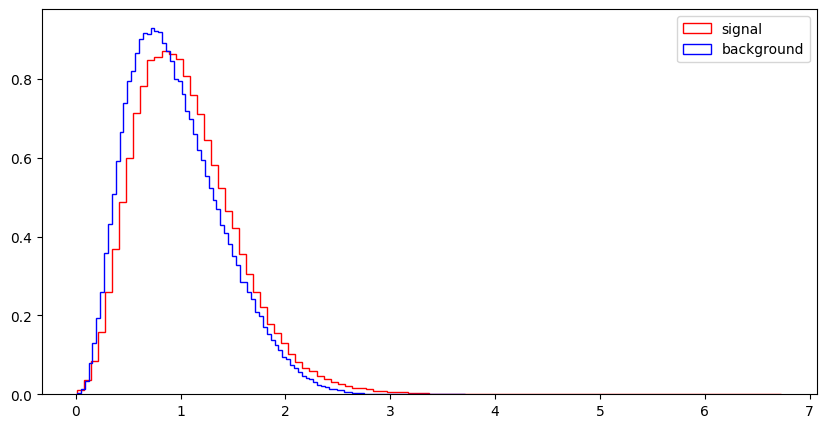

MT2


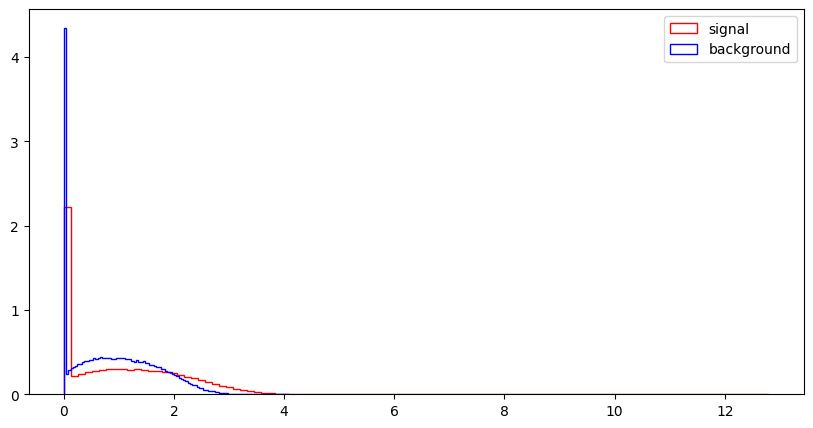

S_R


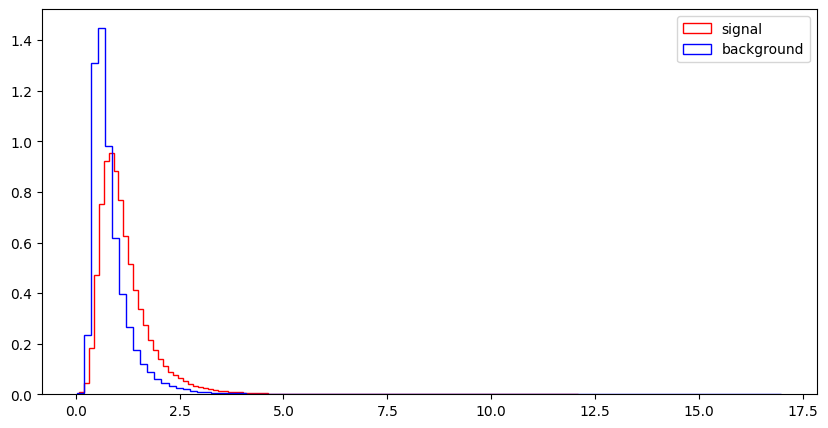

M_Delta_R


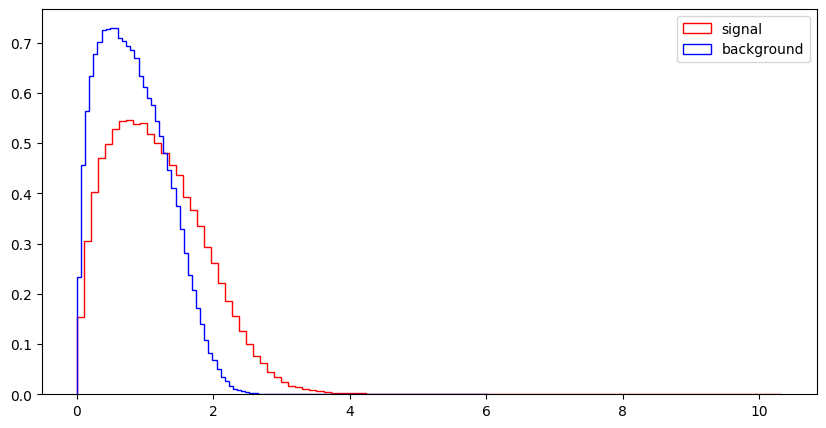

dPhi_r_b


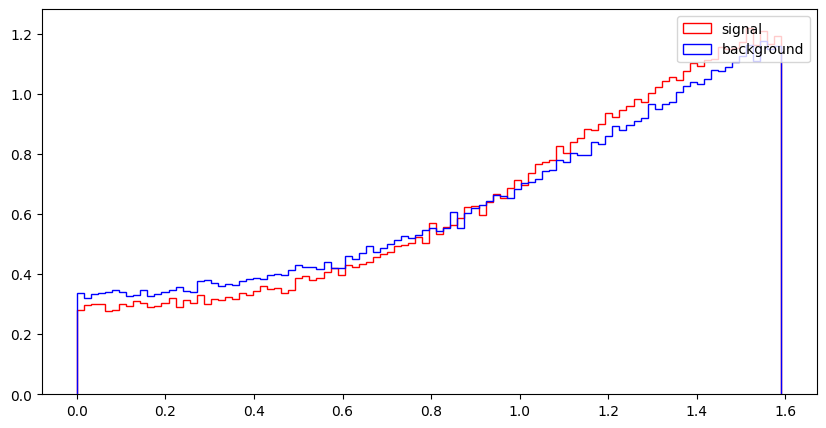

cos_theta_r1


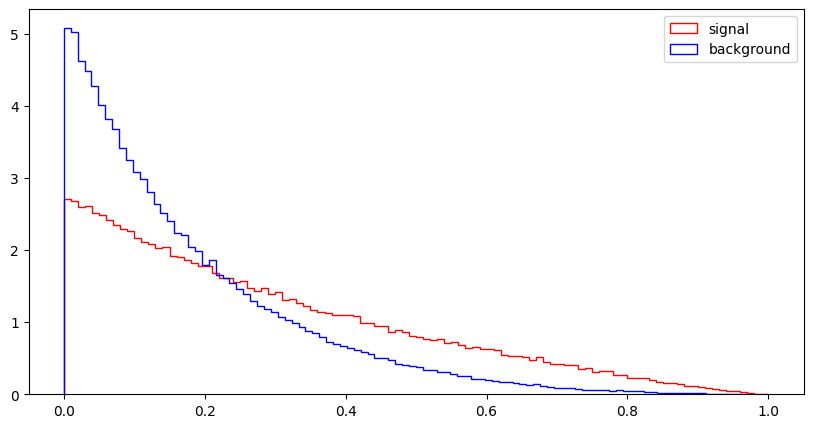

In [ ]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

VarNames = [
    "signal",
    "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi",
    "MET_rel", "axial_MET", "M_R", "M_TR_2",
    "R", "MT2", "S_R", "M_Delta_R",
    "dPhi_r_b", "cos_theta_r1"
]

data = pd.read_csv(
    "/content/SUSY-small.csv",
    header=None,
    names=VarNames
)

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (500000, 19)
   signal    l_1_pT   l_1_eta   l_1_phi    l_2_pT   l_2_eta   l_2_phi  \
0     0.0  0.972861  0.653855  1.176225  1.157156 -1.739873 -0.874309   
1     1.0  1.667973  0.064191 -1.225171  0.506102 -0.338939  1.672543   
2     1.0  0.444840 -0.134298 -0.709972  0.451719 -1.613871 -0.768661   
3     1.0  0.381256 -0.976145  0.693152  0.448959  0.891753 -0.677328   
4     1.0  1.309996 -0.690089 -0.676259  1.589283 -0.693326  0.622907   

        MET   MET_phi   MET_rel  axial_MET       M_R    M_TR_2         R  \
0  0.567765 -0.175000  0.810061  -0.252552  1.921887  0.889637  0.410772   
1  3.475464 -1.219136  0.012955   3.775174  1.045977  0.568051  0.481928   
2  1.219918  0.504026  1.831248  -0.431385  0.526283  0.941514  1.587535   
3  2.033060  1.533041  3.046260  -1.005285  0.569386  1.015211  1.582217   
4  1.087562 -0.381742  0.589204   1.365479  1.179295  0.968218  0.728563   

        MT2       S_R  M_Delta_R  dPhi_r_b  cos_theta_r1  
0  1.145621  1.93

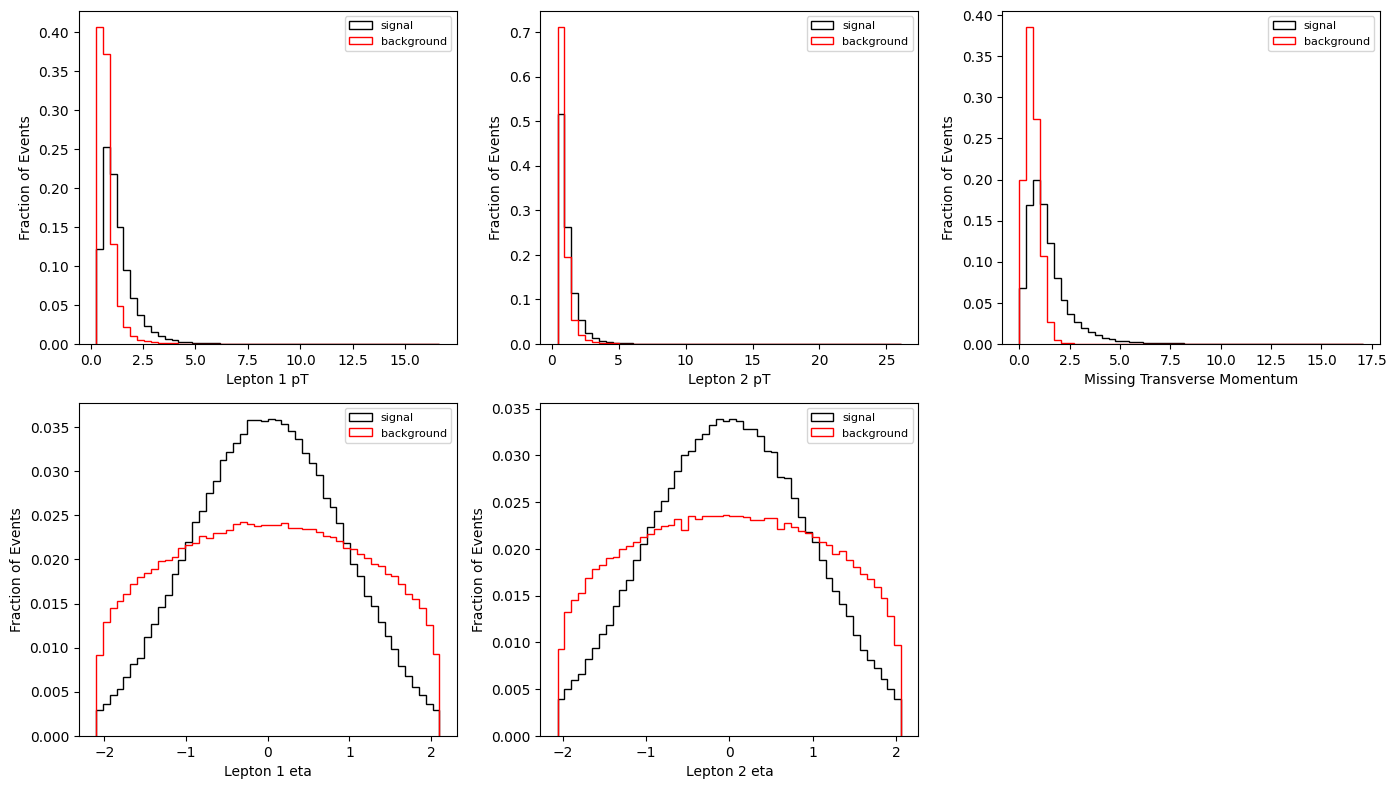

In [ ]:
raw_features = [
    ("l_1_pT", "Lepton 1 pT"),
    ("l_2_pT", "Lepton 2 pT"),
    ("MET", "Missing Transverse Momentum"),
    ("l_1_eta", "Lepton 1 eta"),
    ("l_2_eta", "Lepton 2 eta")
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

signal = data[data["signal"] == 1]
background = data[data["signal"] == 0]

for i, (feature, label) in enumerate(raw_features):
    ax = axes[i]


    values = data[feature].dropna()
    bins = np.histogram_bin_edges(values, bins=50)

    ax.hist(
        signal[feature].dropna(),
        bins=bins,
        weights=np.ones(len(signal[feature].dropna()))
                / len(signal[feature].dropna()),
        histtype="step",
        color="black",
        label="signal"
    )

    ax.hist(
        background[feature].dropna(),
        bins=bins,
        weights=np.ones(len(background[feature].dropna()))
                / len(background[feature].dropna()),
        histtype="step",
        color="red",
        label="background"
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of Events")
    ax.legend(fontsize=8)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

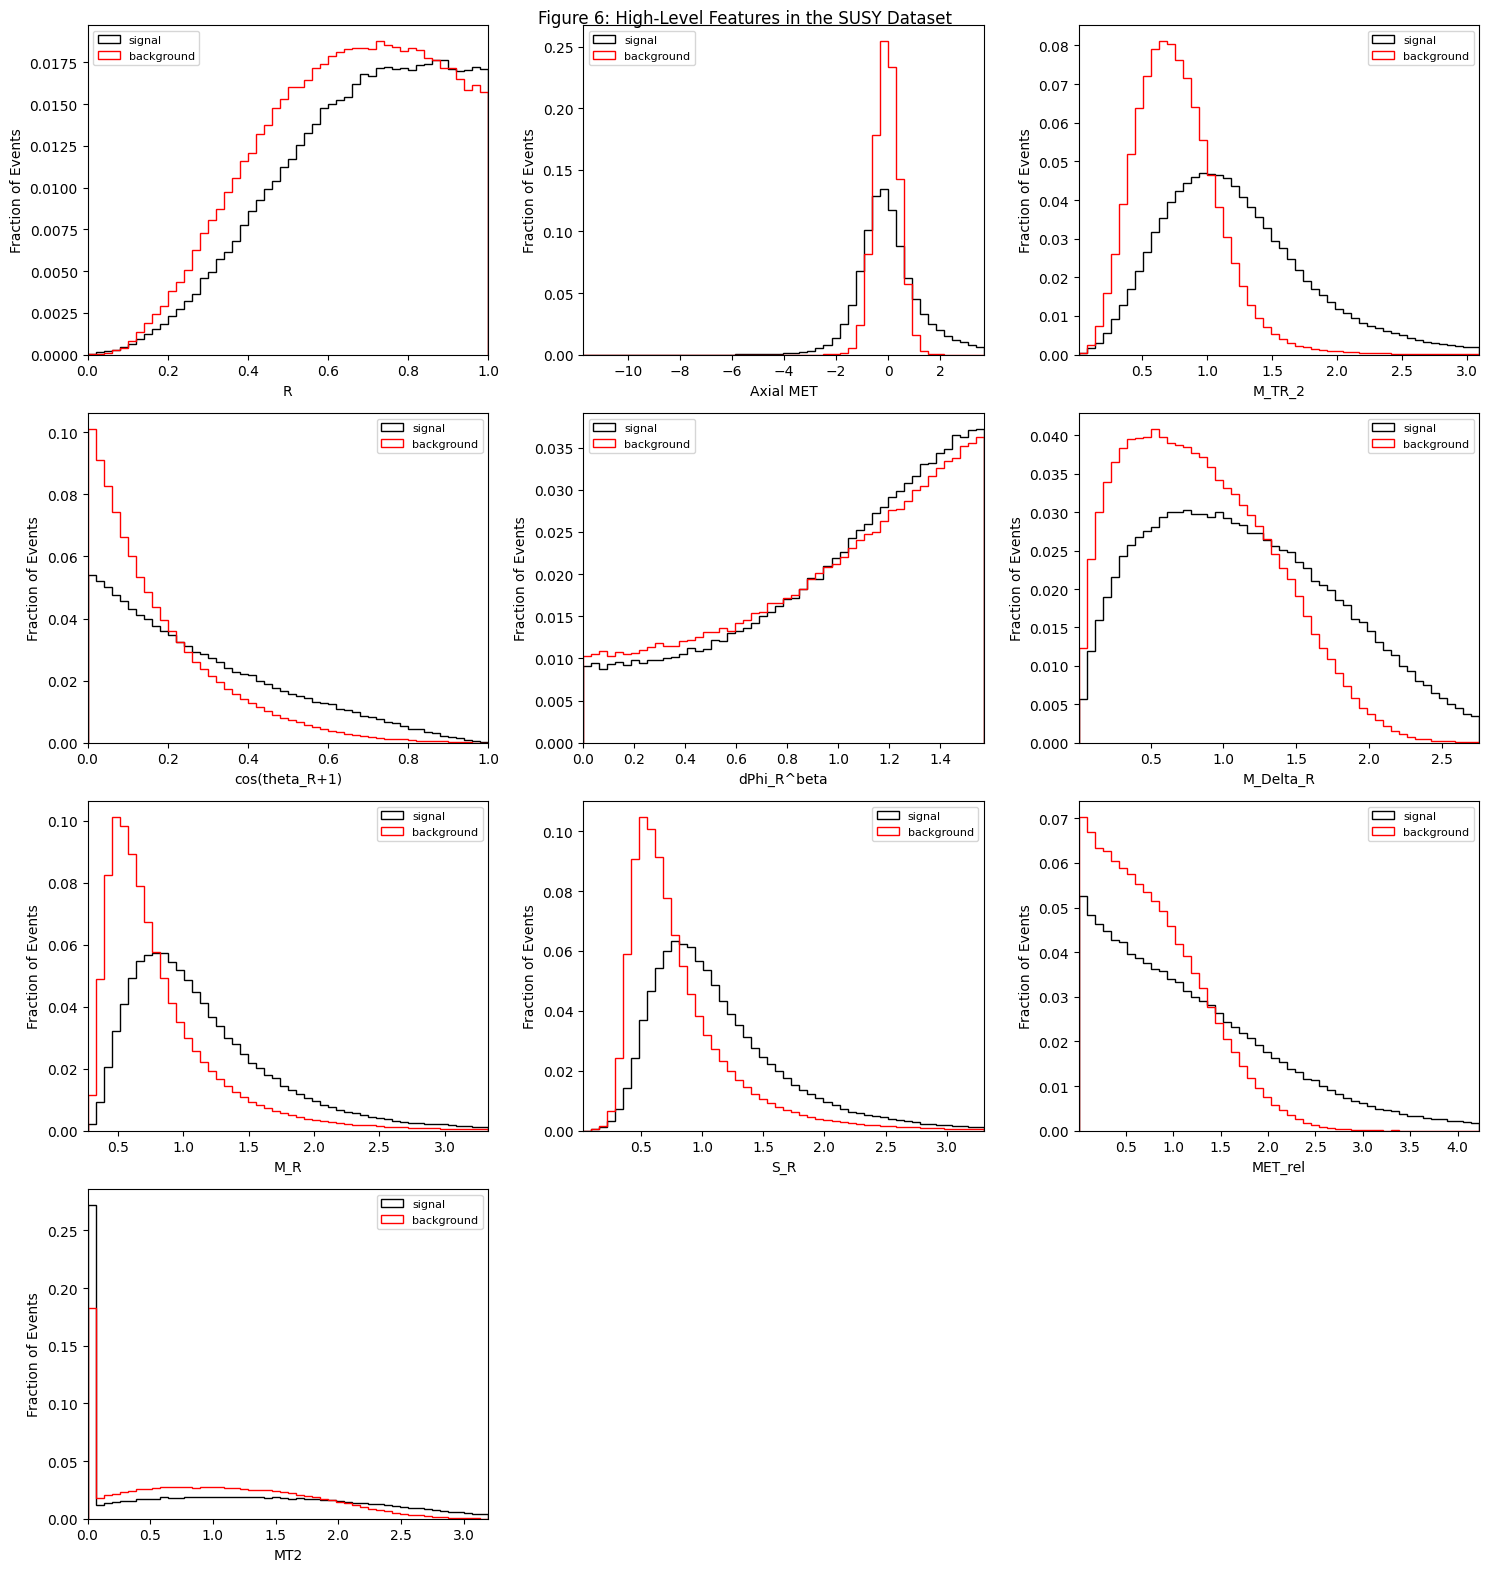

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

high_features = [
    ("R", "R", (0, 1)),
    ("axial_MET", "Axial MET", None),
    ("M_TR_2", "M_TR_2", None),
    ("cos_theta_r1", "cos(theta_R+1)", (0, 1)),
    ("dPhi_r_b", "dPhi_R^beta", (0, np.pi / 2)),
    ("M_Delta_R", "M_Delta_R", None),
    ("M_R", "M_R", None),
    ("S_R", "S_R", None),
    ("MET_rel", "MET_rel", None),
    ("MT2", "MT2", None)
]

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, (feature, label, x_range) in enumerate(high_features):
    ax = axes[i]

    sig = df_sig[feature].dropna()
    bkg = df_bkg[feature].dropna()

    if x_range is None:
        combined = df[feature].dropna()
        xmin = max(0, combined.min()) if feature != "axial_MET" else combined.min()
        xmax = combined.quantile(0.99)
    else:
        xmin, xmax = x_range

    bins = np.linspace(xmin, xmax, 51)

    ax.hist(
        sig, bins=bins,
        weights=np.ones(len(sig)) / len(sig),
        histtype="step", color="black", label="signal"
    )
    ax.hist(
        bkg, bins=bins,
        weights=np.ones(len(bkg)) / len(bkg),
        histtype="step", color="red", label="background"
    )

    ax.set_xlim(xmin, xmax)
    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of Events")
    ax.legend(fontsize=8)

for i in range(len(high_features), len(axes)):
    axes[i].axis("off")

fig.suptitle("Figure 6: High-Level Features in the SUSY Dataset")
plt.tight_layout()
plt.show()

# Used ML to help build these graphs as the original differed far too much from what I was expecting from the paper.

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [59]:

import matplotlib.pyplot as plt
import numpy as np

def pair_plots_compare(df_sig, df_bkg, features):
    n = len(features)
    sig_sample = df_sig.sample(
        n=min(3000, len(df_sig)), random_state=1
    )
    bkg_sample = df_bkg.sample(
        n=min(3000, len(df_bkg)), random_state=1
    )

    fig, axes = plt.subplots(
        n, n, figsize=(2 * n, 2 * n), squeeze=False
    )

    for i, y_feature in enumerate(features):
        for j, x_feature in enumerate(features):
            ax = axes[i, j]

            if i == j:
                ax.hist(
                    df_sig[x_feature].dropna(),
                    bins=30,
                    density=True,
                    histtype="step",
                    linewidth=1.8,
                    color="black",
                    label="Signal"
                )
                ax.hist(
                    df_bkg[x_feature].dropna(),
                    bins=30,
                    density=True,
                    histtype="step",
                    linewidth=1.8,
                    color="red",
                    label="Background"
                )
            else:

                ax.scatter(
                    sig_sample[x_feature],
                    sig_sample[y_feature],
                    s=3,
                    alpha=0.25,
                    color="black"
                )
                ax.scatter(
                    bkg_sample[x_feature],
                    bkg_sample[y_feature],
                    s=3,
                    alpha=0.25,
                    color="red"
                )

            if i == n - 1:
                ax.set_xlabel(x_feature, fontsize=8)
            else:
                ax.set_xticklabels([])

            if j == 0:
                ax.set_ylabel(y_feature, fontsize=8)
            else:
                ax.set_yticklabels([])

            ax.tick_params(axis="both", labelsize=7)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", fontsize=9)

    fig.suptitle("Signal vs Background: Pair Plots", y=1.002)
    plt.tight_layout()
    plt.show()

# Used an LLM because I did not know how to start the code to create the pair plot here

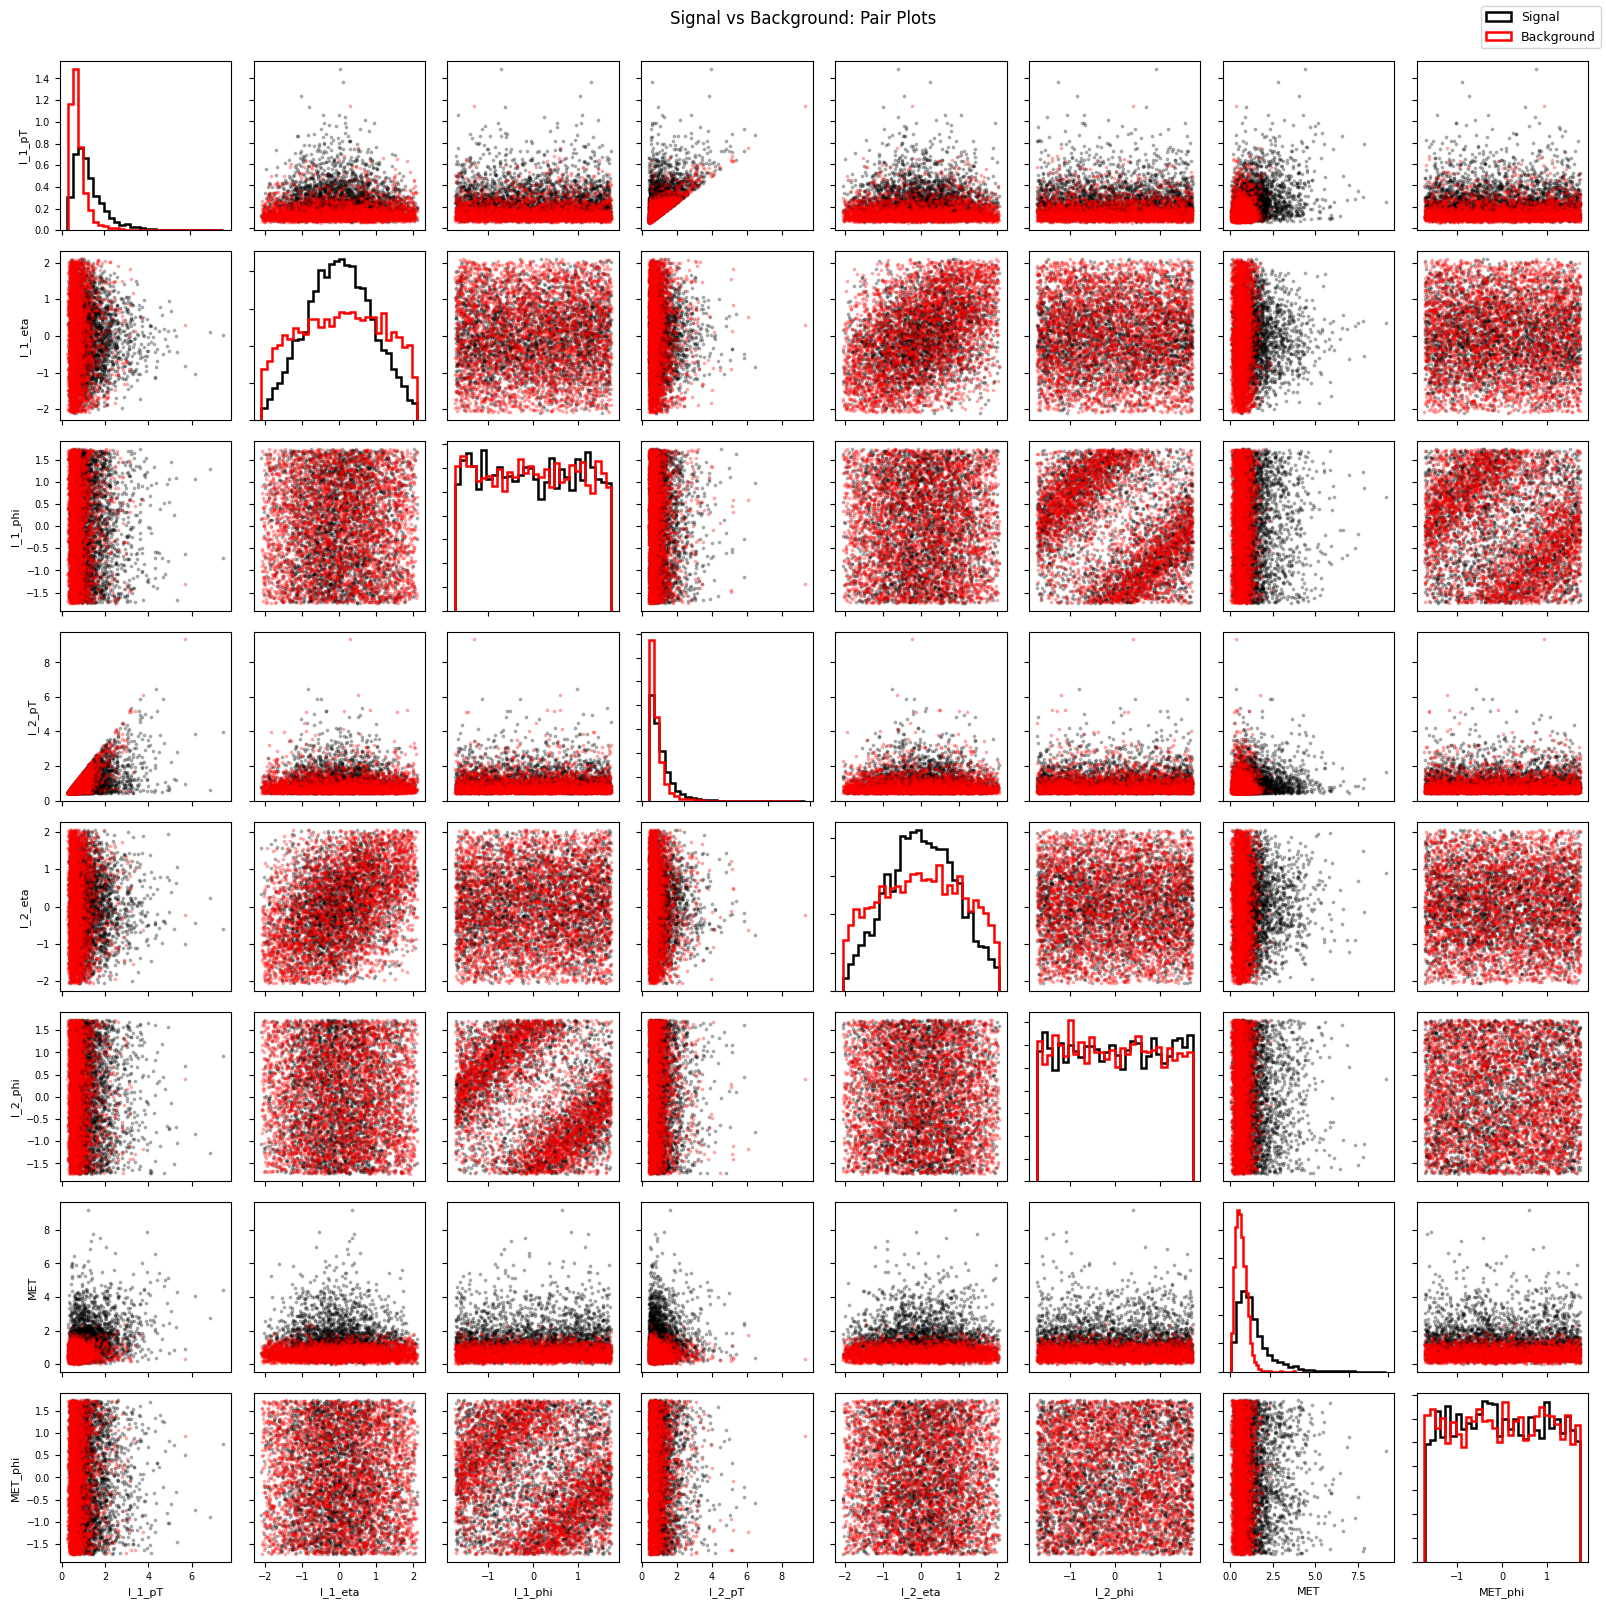

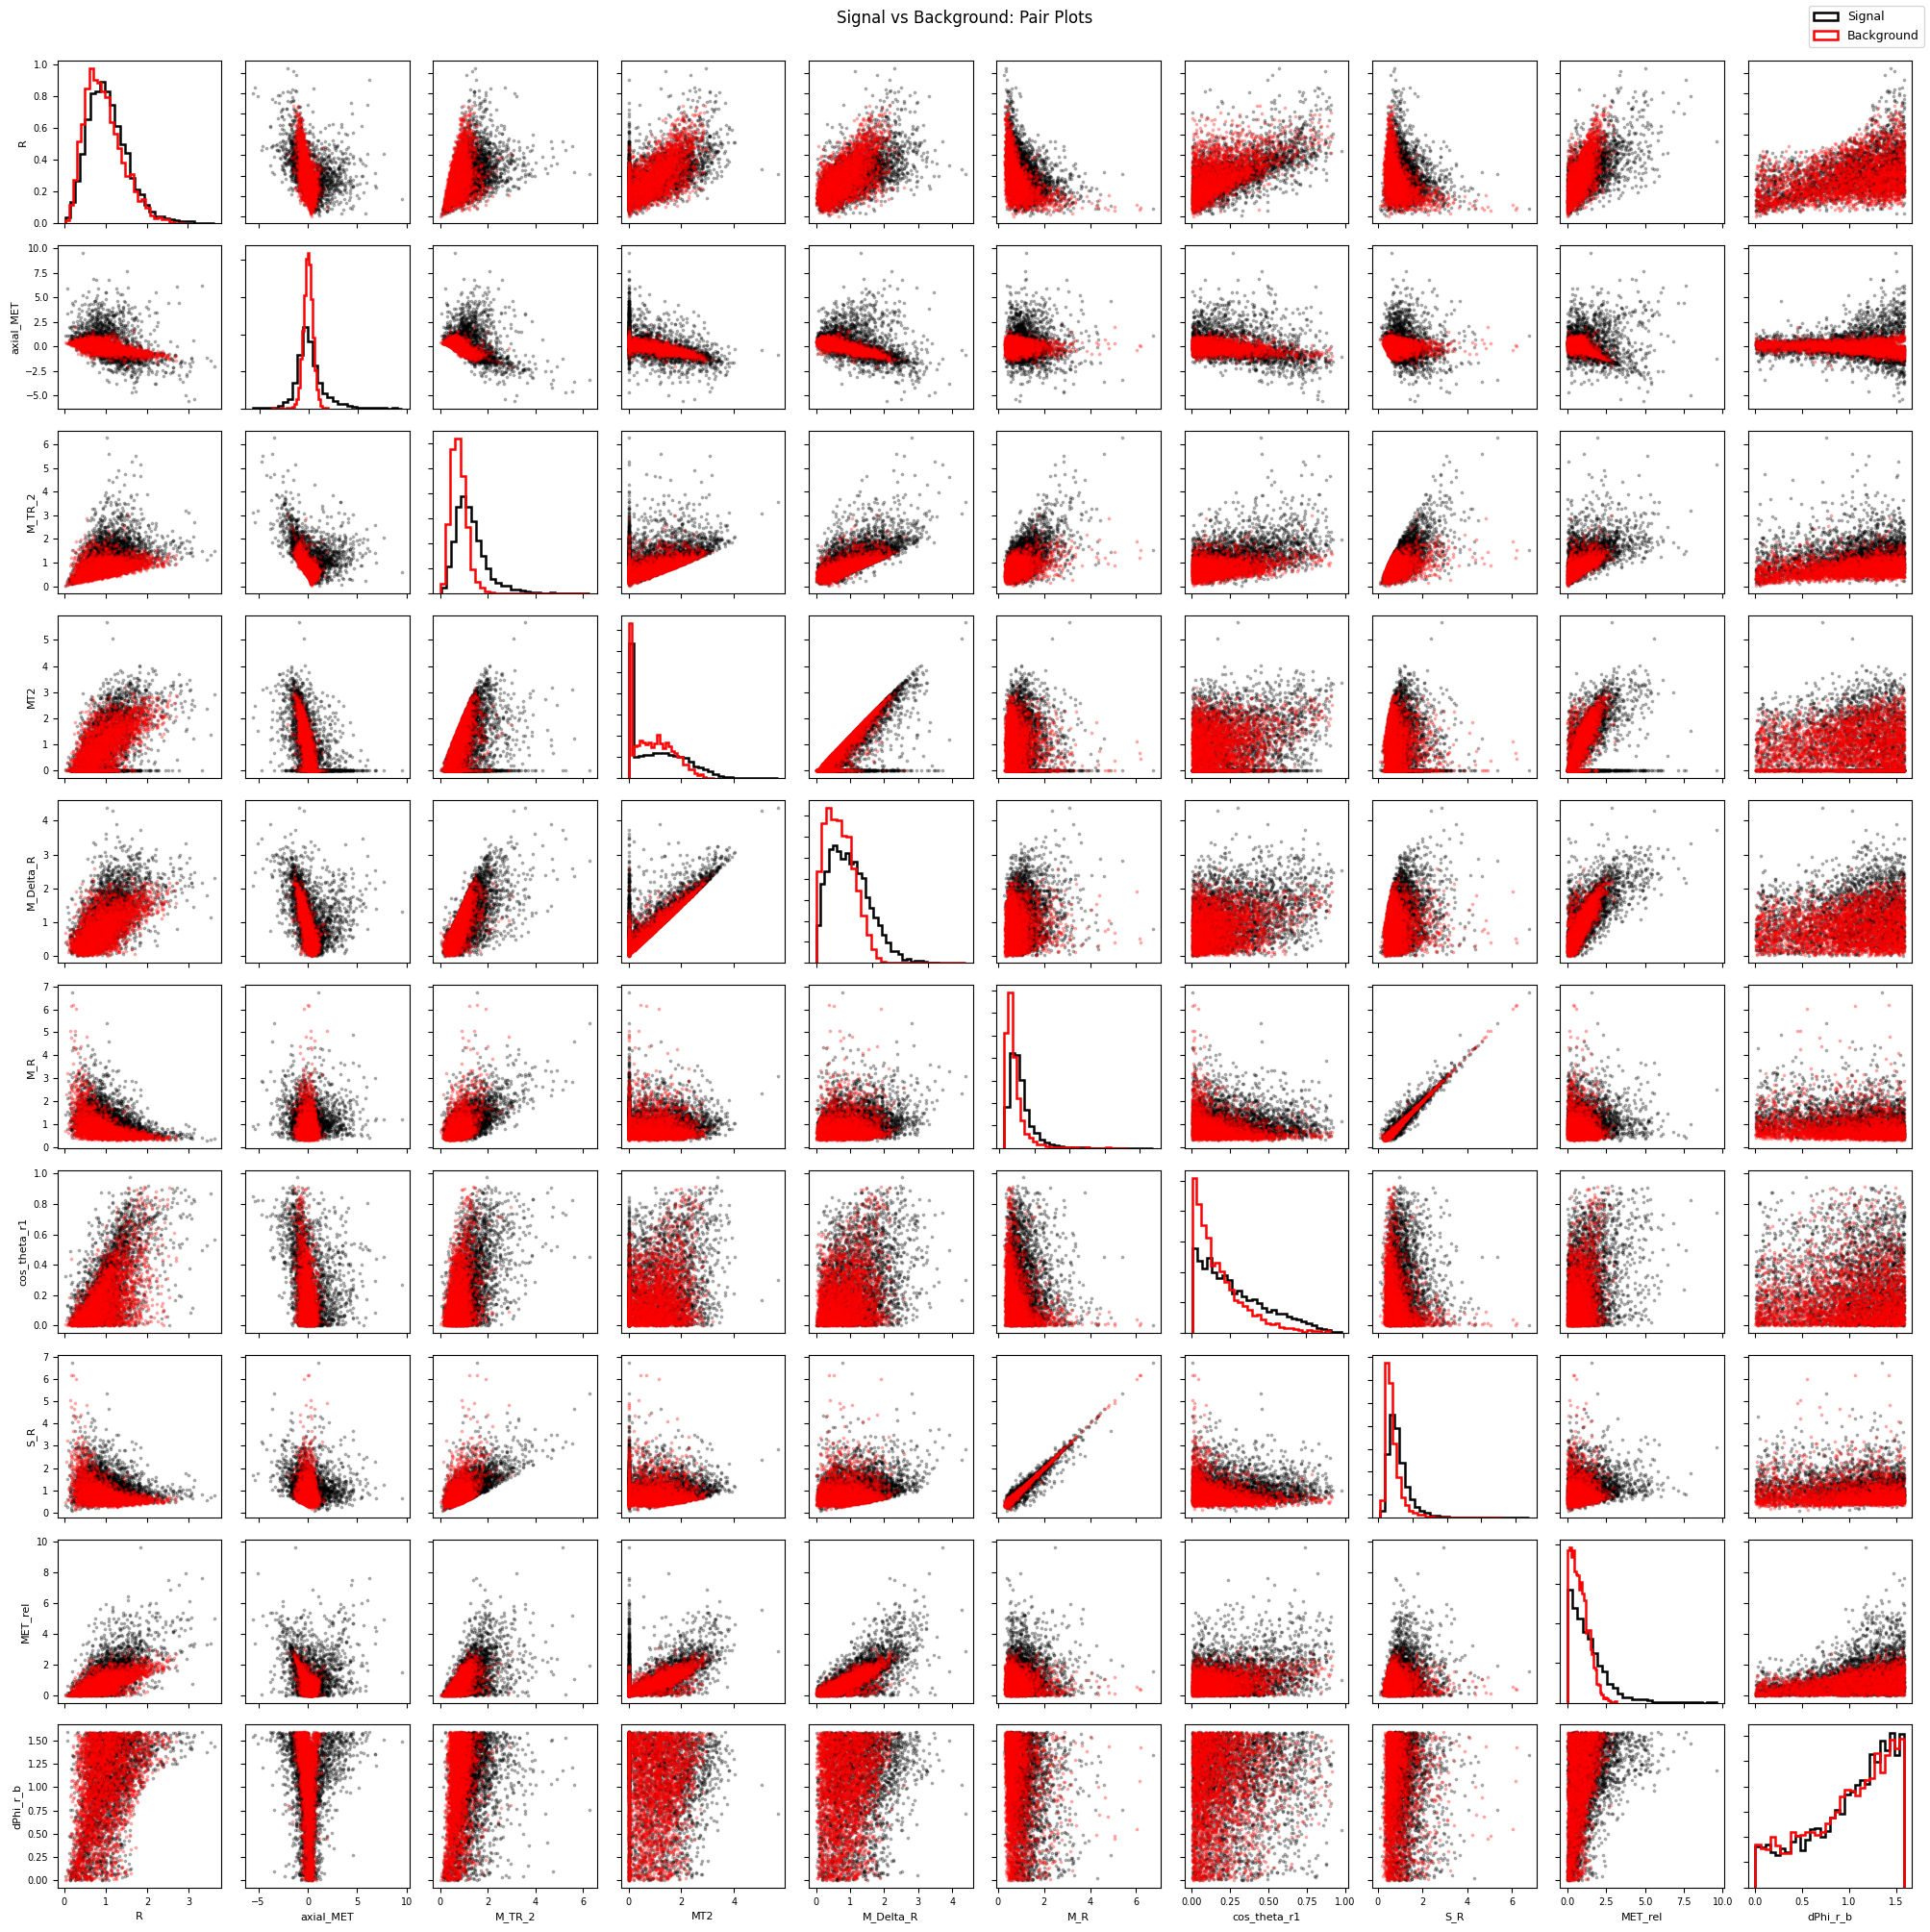

In [60]:

df_sig_5000 = df_sig.sample(n=min(5000, len(df_sig)), random_state=42)
df_bkg_5000 = df_bkg.sample(n=min(5000, len(df_bkg)), random_state=42)


pair_plots_compare(df_sig_5000, df_bkg_5000, low_features)
pair_plots_compare(df_sig_5000, df_bkg_5000, high_features)

4.1B: I reduced the amount of sample that were used for this by randomly selecting 5000 different sample from the dataset. This reduced the amount of data that had to be processed.
4.1C: The best observables for separating signal from background are those with the least overlap between the 2 classes. With this information I'd use the cos_theta_r1 observable as is it seems to have the least amount of overlap compared to the rest.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate).

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [61]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [63]:
import numpy as np


all_features = VarNames[1:]


cov_all = np.cov(df[all_features].to_numpy(), rowvar=False)
corr_all = np.corrcoef(df[all_features].to_numpy(), rowvar=False)

cov_low = np.cov(df[low_features].to_numpy(), rowvar=False)
corr_low = np.corrcoef(df[low_features].to_numpy(), rowvar=False)

cov_high = np.cov(df[high_features].to_numpy(), rowvar=False)
corr_high = np.corrcoef(df[high_features].to_numpy(), rowvar=False)

print("All observables:", cov_all.shape, corr_all.shape)
print("Low-level features:", cov_low.shape, corr_low.shape)
print("High-level features:", cov_high.shape, corr_high.shape)

All observables: (18, 18) (18, 18)
Low-level features: (8, 8) (8, 8)
High-level features: (10, 10) (10, 10)


In [69]:

from IPython.display import HTML, display
import tabulate

def show_matrix(matrix, feature_names, title):

    table = [
        [name] + [f"{value:.3f}" for value in row]
        for name, row in zip(feature_names, matrix)
    ]

    headers = ["Feature"] + list(feature_names)


    html_table = tabulate.tabulate(
        table,
        headers=headers,
        tablefmt="html"
    )


    display(HTML(
        f"<h3>{title}</h3>" + html_table
    ))

show_matrix(cov_all, all_features, "Covariance Matrix — All Observables")
show_matrix(corr_all, all_features, "Correlation Matrix — All Observables")

show_matrix(cov_low, low_features, "Covariance Matrix — Low-Level Features")
show_matrix(corr_low, low_features, "Correlation Matrix — Low-Level Features")

show_matrix(cov_high, high_features, "Covariance Matrix — High-Level Features")
show_matrix(corr_high, high_features, "Correlation Matrix — High-Level Features")



Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Feature,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
R,0.222,-0.181,0.104,0.232,0.165,-0.113,0.058,-0.083,0.249,0.087
axial_MET,-0.181,1.005,-0.185,-0.461,-0.233,0.017,-0.054,-0.041,-0.12,-0.025
M_TR_2,0.104,-0.185,0.338,0.189,0.242,0.21,0.052,0.228,0.302,0.058
MT2,0.232,-0.461,0.189,0.738,0.433,-0.037,0.045,-0.011,0.409,0.021
M_Delta_R,0.165,-0.233,0.242,0.433,0.389,0.074,0.039,0.096,0.415,0.042
M_R,-0.113,0.017,0.21,-0.037,0.074,0.392,-0.014,0.38,0.044,-0.029
cos_theta_r1,0.058,-0.054,0.052,0.045,0.039,-0.014,0.039,-0.01,0.055,0.009
S_R,-0.083,-0.041,0.228,-0.011,0.096,0.38,-0.01,0.382,0.082,-0.003
MET_rel,0.249,-0.12,0.302,0.409,0.415,0.044,0.055,0.082,0.79,0.146
dPhi_r_b,0.087,-0.025,0.058,0.021,0.042,-0.029,0.009,-0.003,0.146,0.19


Feature,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
R,1,-0.383,0.38,0.574,0.564,-0.383,0.627,-0.287,0.595,0.424
axial_MET,-0.383,1,-0.317,-0.535,-0.373,0.027,-0.272,-0.067,-0.134,-0.057
M_TR_2,0.38,-0.317,1,0.379,0.668,0.577,0.451,0.635,0.584,0.229
MT2,0.574,-0.535,0.379,1,0.809,-0.068,0.264,-0.021,0.535,0.056
M_Delta_R,0.564,-0.373,0.668,0.809,1,0.189,0.319,0.249,0.748,0.155
M_R,-0.383,0.027,0.577,-0.068,0.189,1,-0.116,0.981,0.078,-0.106
cos_theta_r1,0.627,-0.272,0.451,0.264,0.319,-0.116,1,-0.085,0.316,0.106
S_R,-0.287,-0.067,0.635,-0.021,0.249,0.981,-0.085,1,0.15,-0.013
MET_rel,0.595,-0.134,0.584,0.535,0.748,0.078,0.316,0.15,1,0.378
dPhi_r_b,0.424,-0.057,0.229,0.056,0.155,-0.106,0.106,-0.013,0.378,1


In [93]:

def analyze_dataset(dataset, low_features, high_features):
    all_features = list(low_features) + list(high_features)


    def analyze_group(features, group_name):
        values = dataset[features].to_numpy()

        covariance = np.cov(values, rowvar=False)
        correlation = np.corrcoef(values, rowvar=False)

        show_matrix(
            covariance,
            features,
            f"{group_name}: Covariance Matrix"
        )

        show_matrix(
            correlation,
            features,
            f"{group_name}: Correlation Matrix"
        )

        return covariance, correlation


    cov_all, corr_all = analyze_group(
        all_features, "All Observables"
    )

    cov_low, corr_low = analyze_group(
        low_features, "Low-Level Features"
    )

    cov_high, corr_high = analyze_group(
        high_features, "High-Level Features"
    )

    return {
        "all": (cov_all, corr_all),
        "low": (cov_low, corr_low),
        "high": (cov_high, corr_high)
    }
  # Used an LLM here to begin writing the code as I did not know how to begin and then debug it


In [71]:

results = analyze_dataset(df, low_features, high_features)


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,-0.06,-0.01,0.287,-0.012,0.098,0.364,0.022,0.343,0.098,-0.047
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,0,-0.001,-0.001,0,-0.001,-0.001,0,-0.001,-0.001,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0,-0.002,0.001,0.001,0.001,0.001,0,0.001,0.001,0.001
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.099,0.051,0.163,-0.069,0.006,0.325,-0.028,0.322,-0.001,-0.004
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0,-0.001,0,0.001,0.001,-0.001,0,-0.001,0.001,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.002,0.001,0.001,0,0.001,0.001,-0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.188,0.154,0.365,0.155,0.315,0.145,0.073,0.166,0.546,0.146
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0,-0,-0.001,0,-0.001,-0.001,0,-0.002,-0.005,-0.002
R,-0.06,0,0,-0.099,0,0.001,0.188,-0,0.222,-0.181,0.104,0.232,0.165,-0.113,0.058,-0.083,0.249,0.087
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.181,1.005,-0.185,-0.461,-0.233,0.017,-0.054,-0.041,-0.12,-0.025


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,-0.186,-0.014,0.723,-0.021,0.229,0.851,0.165,0.811,0.16,-0.157
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,0.001,-0.001,-0.001,0,-0.002,-0.001,0.002,-0.001,-0.002,-0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0,-0.002,0.001,0.001,0.001,0.002,0.001,0.002,0.001,0.002
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.324,0.078,0.43,-0.123,0.014,0.797,-0.217,0.799,-0.001,-0.013
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,0,0.002,0.001,-0.001,0.001,-0.001,0.001,-0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.001,-0.002,0.001,0.003,0.002,0.001,0,0.001,0.002,-0.001
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.457,0.176,0.72,0.206,0.579,0.264,0.425,0.307,0.704,0.383
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0,-0,-0.002,0,-0.001,-0.002,0.001,-0.003,-0.005,-0.004
R,-0.186,0.001,0,-0.324,0.001,0.001,0.457,-0,1,-0.383,0.38,0.574,0.564,-0.383,0.627,-0.287,0.595,0.424
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.383,1,-0.317,-0.535,-0.373,0.027,-0.272,-0.067,-0.134,-0.057


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Feature,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Feature,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
R,0.222,-0.181,0.104,0.232,0.165,-0.113,0.058,-0.083,0.249,0.087
axial_MET,-0.181,1.005,-0.185,-0.461,-0.233,0.017,-0.054,-0.041,-0.12,-0.025
M_TR_2,0.104,-0.185,0.338,0.189,0.242,0.21,0.052,0.228,0.302,0.058
MT2,0.232,-0.461,0.189,0.738,0.433,-0.037,0.045,-0.011,0.409,0.021
M_Delta_R,0.165,-0.233,0.242,0.433,0.389,0.074,0.039,0.096,0.415,0.042
M_R,-0.113,0.017,0.21,-0.037,0.074,0.392,-0.014,0.38,0.044,-0.029
cos_theta_r1,0.058,-0.054,0.052,0.045,0.039,-0.014,0.039,-0.01,0.055,0.009
S_R,-0.083,-0.041,0.228,-0.011,0.096,0.38,-0.01,0.382,0.082,-0.003
MET_rel,0.249,-0.12,0.302,0.409,0.415,0.044,0.055,0.082,0.79,0.146
dPhi_r_b,0.087,-0.025,0.058,0.021,0.042,-0.029,0.009,-0.003,0.146,0.19


Feature,R,axial_MET,M_TR_2,MT2,M_Delta_R,M_R,cos_theta_r1,S_R,MET_rel,dPhi_r_b
R,1,-0.383,0.38,0.574,0.564,-0.383,0.627,-0.287,0.595,0.424
axial_MET,-0.383,1,-0.317,-0.535,-0.373,0.027,-0.272,-0.067,-0.134,-0.057
M_TR_2,0.38,-0.317,1,0.379,0.668,0.577,0.451,0.635,0.584,0.229
MT2,0.574,-0.535,0.379,1,0.809,-0.068,0.264,-0.021,0.535,0.056
M_Delta_R,0.564,-0.373,0.668,0.809,1,0.189,0.319,0.249,0.748,0.155
M_R,-0.383,0.027,0.577,-0.068,0.189,1,-0.116,0.981,0.078,-0.106
cos_theta_r1,0.627,-0.272,0.451,0.264,0.319,-0.116,1,-0.085,0.316,0.106
S_R,-0.287,-0.067,0.635,-0.021,0.249,0.981,-0.085,1,0.15,-0.013
MET_rel,0.595,-0.134,0.584,0.535,0.748,0.078,0.316,0.15,1,0.378
dPhi_r_b,0.424,-0.057,0.229,0.056,0.155,-0.106,0.106,-0.013,0.378,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal:

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable.

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

l_1_pT - rule 1
l_1_eta - rule 4
l_1_phi - rule 1
l_2_pT rule 1
l_2_eta - rule 4
l_2_phi rule 2
MET - rule 1
MET_phi - rule 1
MET_rel rule 1
axial_MET rule 3
M_R rule 1
M_TR_2 Rule 1
R Rule 1
MT2 Rule 1
S_R rule 1
M_delta_R rule 1
dPhi_r_b rule 3
cos_theta_r1 rule 1



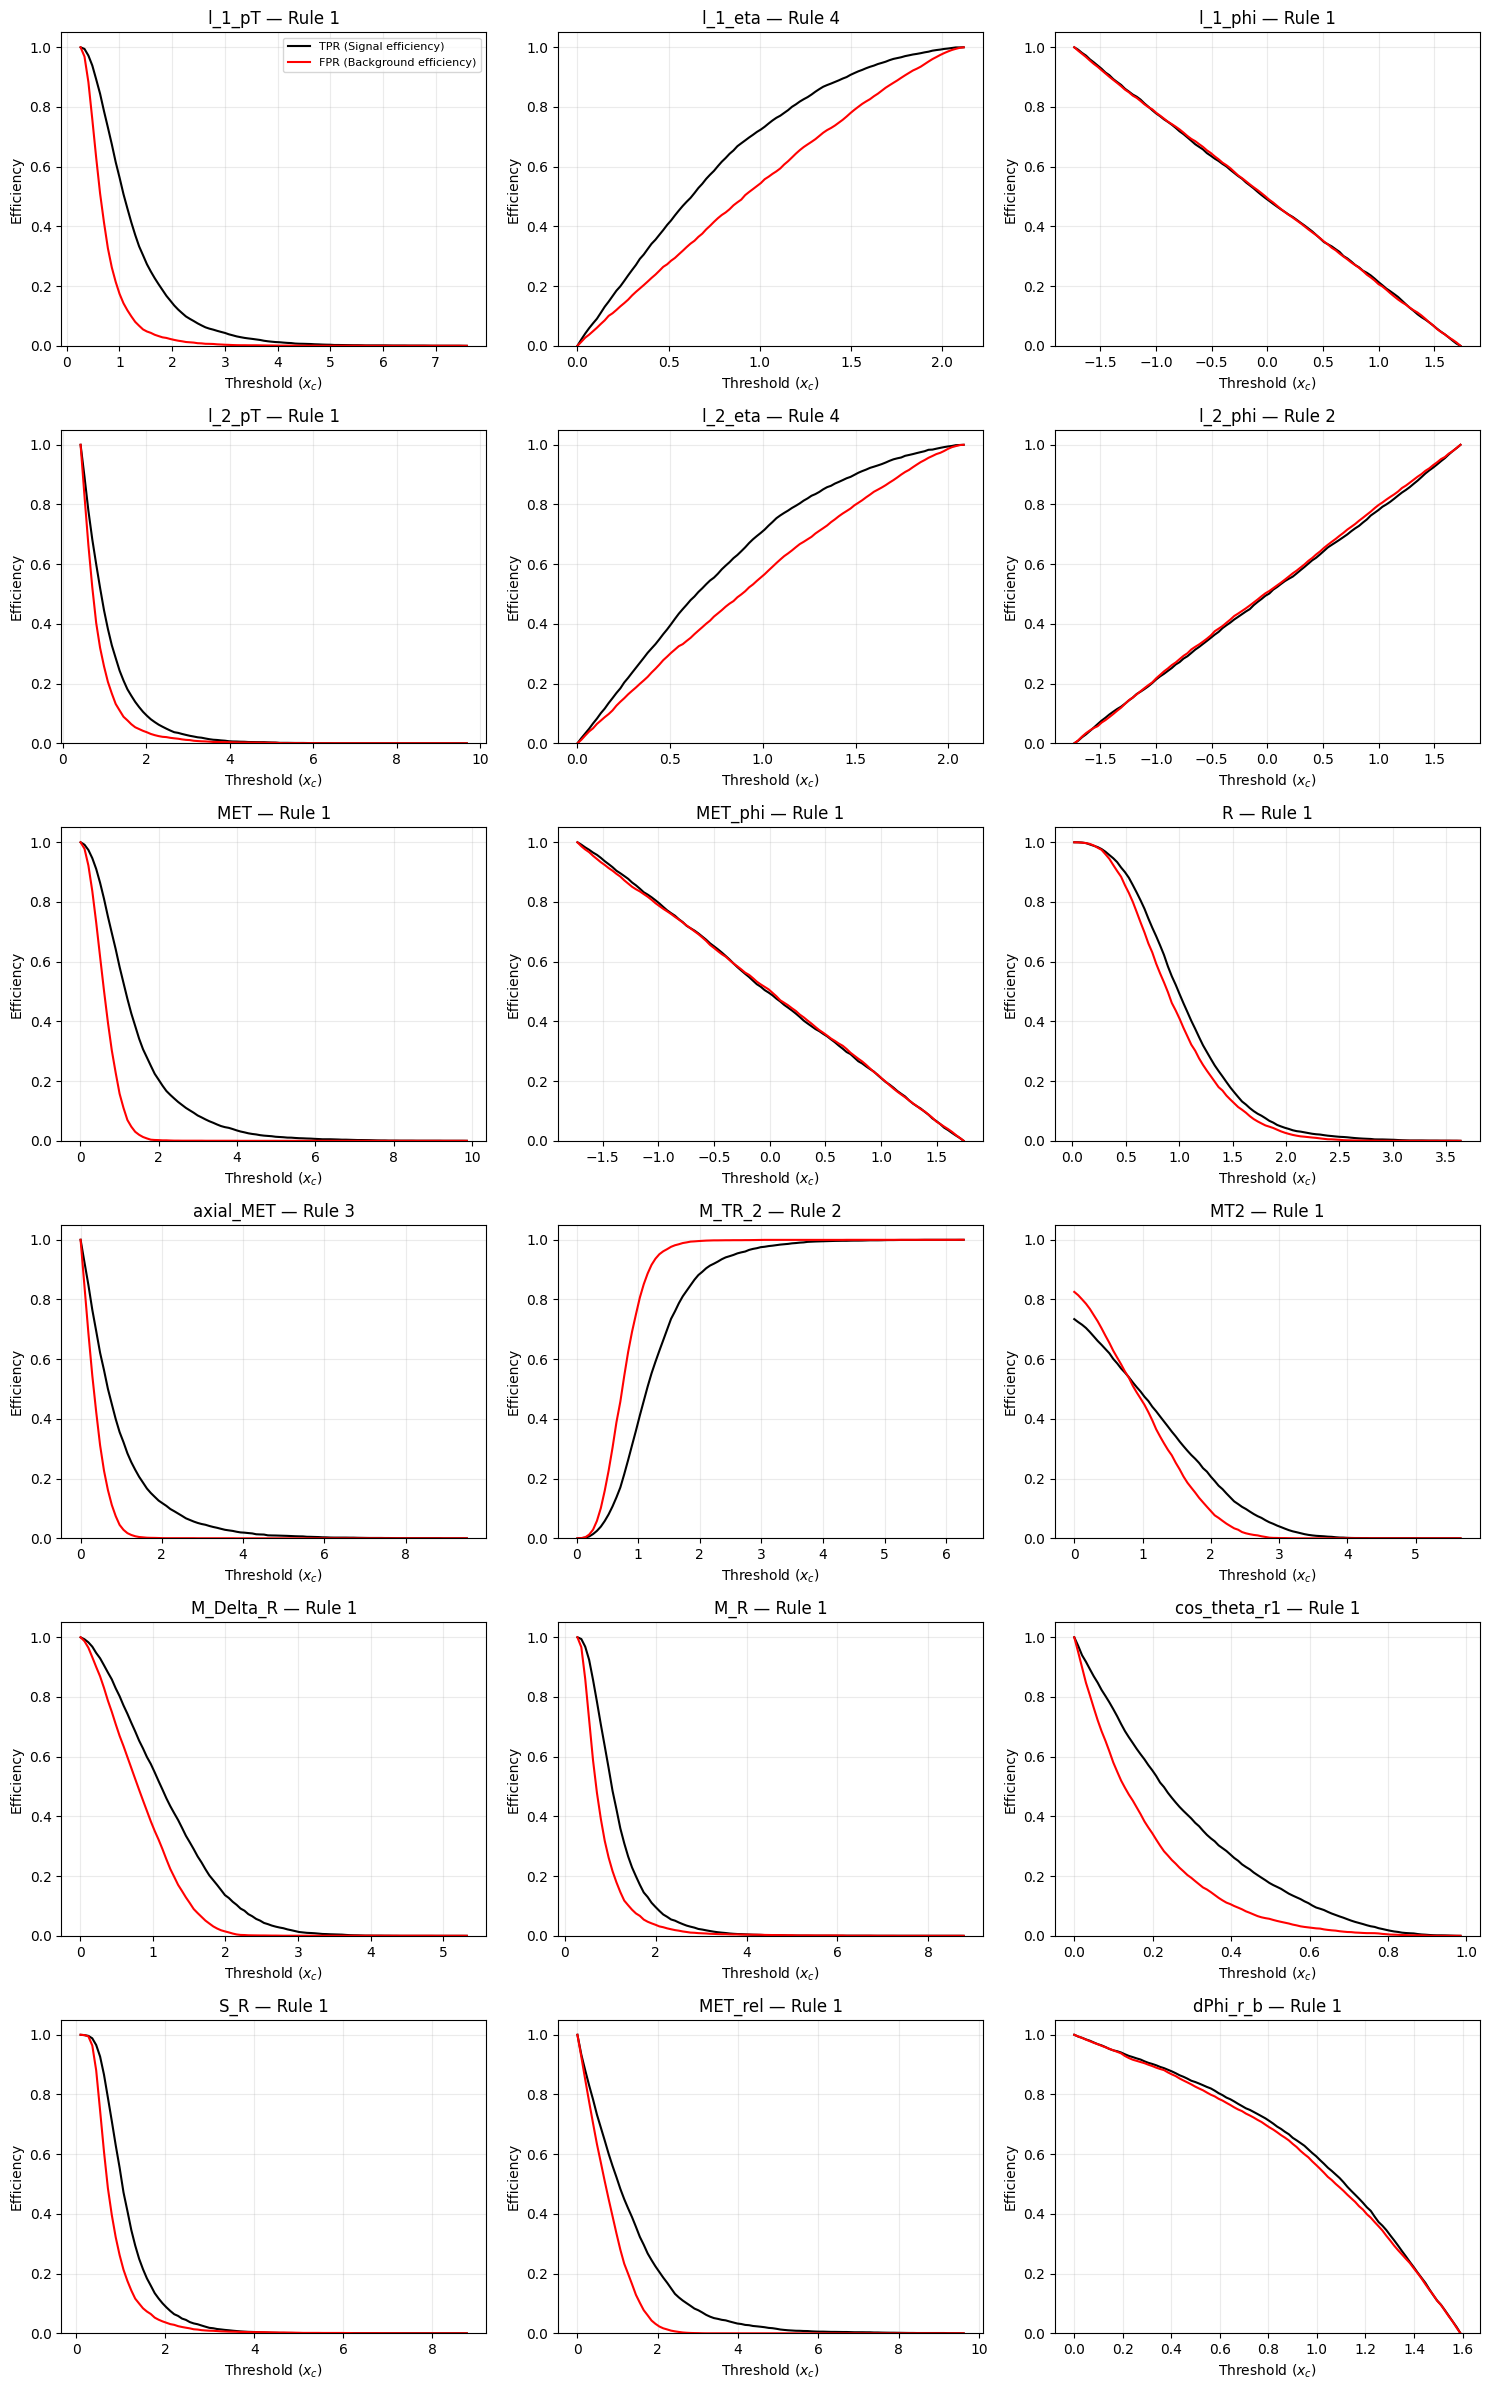

In [73]:
import numpy as np
import matplotlib.pyplot as plt


sig = df_sig.sample(n=min(5000, len(df_sig)), random_state=42)
bkg = df_bkg.sample(n=min(5000, len(df_bkg)), random_state=42)

all_features = list(low_features) + list(high_features)



rules = {
    "l_1_pT": 1,
    "l_1_eta": 4,
    "l_1_phi": 1,
    "l_2_pT": 1,
    "l_2_eta": 4,
    "l_2_phi": 2,
    "MET": 1,
    "MET_phi": 1,
    "MET_rel": 1,
    "axial_MET": 3,
    "M_R": 1,
    "M_TR_2": 2,
    "R": 1,
    "MT2": 1,
    "S_R": 1,
    "M_Delta_R": 1,
    "dPhi_r_b": 1,
    "cos_theta_r1": 1
}


def calculate_efficiencies(signal, background, rule):
    signal = np.asarray(signal)
    background = np.asarray(background)


    mu = np.mean(np.concatenate([signal, background]))

    if rule == 3 or rule == 4:
        signal = np.abs(signal - mu)
        background = np.abs(background - mu)


    low = min(signal.min(), background.min())
    high = max(signal.max(), background.max())
    thresholds = np.linspace(low, high, 100)

    tpr = []
    fpr = []

    for xc in thresholds:
        if rule == 1 or rule == 3:
            tpr.append(np.mean(signal > xc))
            fpr.append(np.mean(background > xc))
        else:
            tpr.append(np.mean(signal < xc))
            fpr.append(np.mean(background < xc))

    return thresholds, np.array(tpr), np.array(fpr)



ncols = 3
nrows = int(np.ceil(len(all_features) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 4 * nrows)
)
axes = axes.flatten()

for i, feature in enumerate(all_features):
    rule = rules.get(feature, 1)

    thresholds, tpr, fpr = calculate_efficiencies(
        sig[feature],
        bkg[feature],
        rule
    )

    axes[i].plot(thresholds, tpr, color="black",
                 label="TPR (Signal efficiency)")
    axes[i].plot(thresholds, fpr, color="red",
                 label="FPR (Background efficiency)")

    axes[i].set_title(f"{feature} — Rule {rule}")
    axes[i].set_xlabel("Threshold ($x_c$)")
    axes[i].set_ylabel("Efficiency")
    axes[i].set_ylim(0, 1.05)
    axes[i].grid(alpha=0.25)

    if i == 0:
        axes[i].legend(fontsize=8)

for i in range(len(all_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Used an LLM to debug the axes part of the code

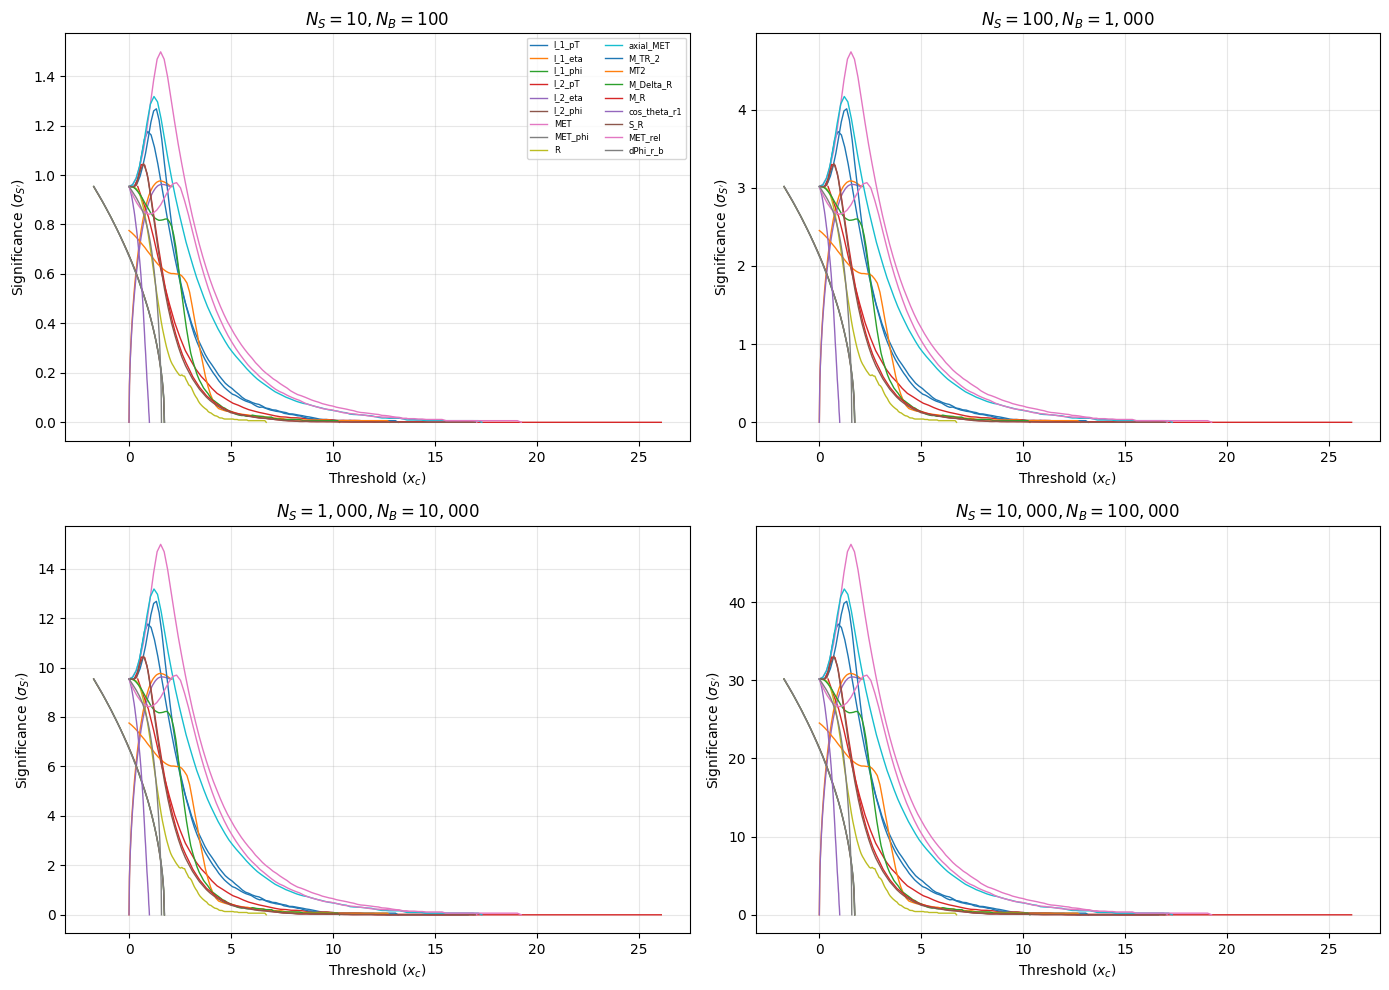

In [75]:
import numpy as np
import matplotlib.pyplot as plt

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]


all_features = list(low_features) + list(high_features)


selection_rules = {
    "l_1_pT": 1,
    "l_1_eta": 4,
    "l_1_phi": 1,
    "l_2_pT": 1,
    "l_2_eta": 4,
    "l_2_phi": 1,
    "MET": 1,
    "MET_phi": 1,
    "R": 1,
    "axial_MET": 3,
    "M_TR_2": 1,
    "MT2": 1,
    "M_Delta_R": 1,
    "M_R": 1,
    "cos_theta_r1": 1,
    "S_R": 1,
    "MET_rel": 1,
    "dPhi_r_b": 1
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (N_S, N_B) in zip(axes.flat, scenarios):
    for feature in all_features:
        signal = df_sig[feature].dropna().to_numpy()
        background = df_bkg[feature].dropna().to_numpy()

        if len(signal) == 0 or len(background) == 0:
            continue

        rule = selection_rules.get(feature, 1)

        if rule in (3, 4):
            mu = np.mean(np.concatenate([signal, background]))
            signal = np.abs(signal - mu)
            background = np.abs(background - mu)

        low = min(signal.min(), background.min())
        high = max(signal.max(), background.max())
        thresholds = np.linspace(low, high, 100)

        if rule in (1, 3):
            tpr = np.array([np.mean(signal > x) for x in thresholds])
            fpr = np.array([np.mean(background > x) for x in thresholds])
        else:
            tpr = np.array([np.mean(signal < x) for x in thresholds])
            fpr = np.array([np.mean(background < x) for x in thresholds])

        selected_signal = N_S * tpr
        selected_background = N_B * fpr

        significance = np.divide(
            selected_signal,
            np.sqrt(selected_signal + selected_background),
            out=np.zeros_like(selected_signal),
            where=(selected_signal + selected_background) > 0
        )

        ax.plot(
            thresholds,
            significance,
            label=feature,
            linewidth=1
        )

    ax.set_title(f"$N_S={N_S:,}, N_B={N_B:,}$")
    ax.set_xlabel("Threshold ($x_c$)")
    ax.set_ylabel("Significance ($\\sigma_{S'}$)")
    ax.grid(True, alpha=0.3)

axes[0, 0].legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3).

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [77]:
import numpy as np
import pandas as pd
from IPython.display import display

cuts = [
    ("l_1_pT", 1.5),
    ("M_R", 1.0),
    ("M_Delta_R", 1.0)
]

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for scenario, (N_S, N_B) in enumerate(scenarios, start=1):
    sig = df_sig.copy()
    bkg = df_bkg.copy()

    for feature, threshold in cuts:

        sig = sig[sig[feature] > threshold]
        bkg = bkg[bkg[feature] > threshold]


        eps_S = len(sig) / len(df_sig)
        eps_B = len(bkg) / len(df_bkg)


        NS_prime = eps_S * N_S
        NB_prime = eps_B * N_B


        significance = (
            NS_prime / np.sqrt(NS_prime + NB_prime)
            if NS_prime + NB_prime > 0 else 0
        )

        results.append({
            "Scenario": scenario,
            "Cut applied": feature,
            "Threshold": threshold,
            "Signal efficiency": eps_S,
            "Background efficiency": eps_B,
            "Signal remaining": NS_prime,
            "Background remaining": NB_prime,
            "Significance": significance
        })

cutflow = pd.DataFrame(results)
display(cutflow.round(4))

,Scenario,Cut applied,Threshold,Signal efficiency,Background efficiency,Signal remaining,Background remaining,Significance
0,1,l_1_pT,1.5,0.2844,0.0516,2.8442,5.1593,1.0053
1,1,M_R,1.0,0.2825,0.0514,2.8250,5.1419,1.0009
2,1,M_Delta_R,1.0,0.1714,0.0223,1.7142,2.2256,0.8636
3,2,l_1_pT,1.5,0.2844,0.0516,28.4416,51.5928,3.1792
4,2,M_R,1.0,0.2825,0.0514,28.2501,51.4192,3.1650
5,2,M_Delta_R,1.0,0.1714,0.0223,17.1419,22.2563,2.7310
6,3,l_1_pT,1.5,0.2844,0.0516,284.4162,515.9277,10.0535
7,3,M_R,1.0,0.2825,0.0514,282.5013,514.1918,10.0086
8,3,M_Delta_R,1.0,0.1714,0.0223,171.4192,222.5628,8.6362
9,4,l_1_pT,1.5,0.2844,0.0516,2844.1624,5159.2768,31.7919


In [78]:
import numpy as np
import pandas as pd
from IPython.display import display

cut_l1 = 1.5
cut_mr = 1.0


def calculate_significance(signal, background):
    if signal + background == 0:
        return 0
    return signal / np.sqrt(signal + background)


def optimize_second_cut(first_feature, first_cut,
                        second_feature, second_rule,
                        thresholds):


    if first_feature == "l_1_pT":
        sig_first = df_sig[df_sig[first_feature] > first_cut]
        bg_first = df_bkg[df_bkg[first_feature] > first_cut]
    else:
        sig_first = df_sig[df_sig[first_feature] > first_cut]
        bg_first = df_bkg[df_bkg[first_feature] > first_cut]

    results = []

    for threshold in thresholds:
        if second_rule == ">":
            sig_final = sig_first[
                sig_first[second_feature] > threshold
            ]
            bg_final = bg_first[
                bg_first[second_feature] > threshold
            ]
        else:
            sig_final = sig_first[
                sig_first[second_feature] < threshold
            ]
            bg_final = bg_first[
                bg_first[second_feature] < threshold
            ]

        ns = len(sig_final)
        nb = len(bg_final)

        results.append({
            "First cut": first_feature,
            "Second cut": second_feature,
            "Second threshold": threshold,
            "Signal remaining": ns,
            "Background remaining": nb,
            "Significance": calculate_significance(ns, nb)
        })

    return pd.DataFrame(results)



mr_thresholds = np.linspace(
    df_sig["M_R"].min(), df_sig["M_R"].max(), 100
)

l1_thresholds = np.linspace(
    df_sig["l_1_pT"].min(), df_sig["l_1_pT"].max(), 100
)


order1 = optimize_second_cut(
    "l_1_pT", cut_l1, "M_R", ">", mr_thresholds
)


order2 = optimize_second_cut(
    "M_R", cut_mr, "l_1_pT", ">", l1_thresholds
)

print("Order 1: l_1_pT first, then optimize M_R")
display(order1.loc[[order1["Significance"].idxmax()]])

print("Order 2: M_R first, then optimize l_1_pT")
display(order2.loc[[order2["Significance"].idxmax()]])

# Used an LLM for this one to help me write the code because I was having issues writing it

Order 1: l_1_pT first, then optimize M_R


,First cut,Second cut,Second threshold,Signal remaining,Background remaining,Significance
0,l_1_pT,M_R,0.273004,65201,13969,231.725557


Order 2: M_R first, then optimize l_1_pT


,First cut,Second cut,Second threshold,Signal remaining,Background remaining,Significance
5,M_R,l_1_pT,0.880719,111024,45870,280.293936


The results showed that applying M_R cur first actually produced a higher significance than doing it reversed.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



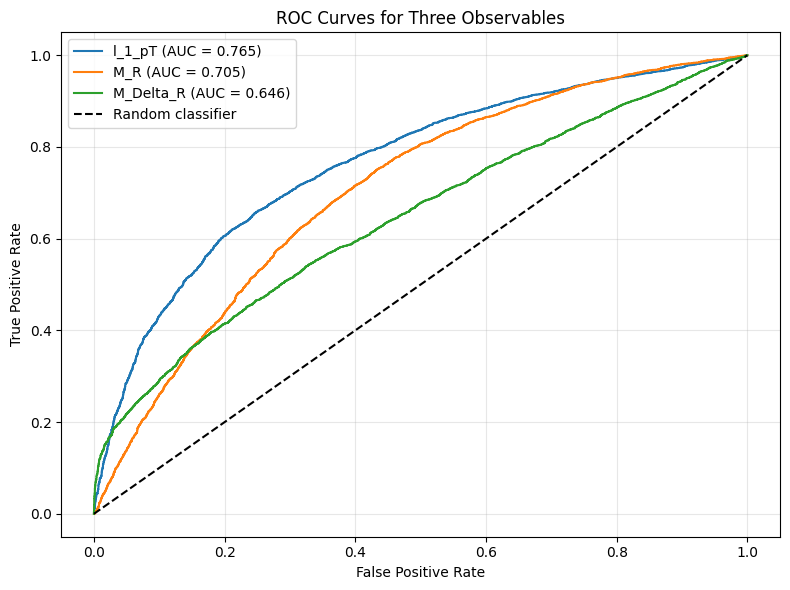

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

n_samples = 5000


features = ["l_1_pT", "M_R", "M_Delta_R"]

fig, ax = plt.subplots(figsize=(8, 6))

for feature in features:

    signal = df_sig[feature].iloc[:n_samples].to_numpy()
    background = df_bkg[feature].iloc[:n_samples].to_numpy()


    y_true = np.concatenate([
        np.ones(len(signal)),
        np.zeros(len(background))
    ])
    scores = np.concatenate([signal, background])


    fpr, tpr, thresholds = roc_curve(y_true, scores)
    roc_auc = auc(fpr, tpr)


    if roc_auc < 0.5:
        fpr, tpr, thresholds = roc_curve(y_true, -scores)
        roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, label=f"{feature} (AUC = {roc_auc:.3f})")


ax.plot([0, 1], [0, 1], "k--", label="Random classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves for Three Observables")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

def plot_roc_curves(df_sig, df_bkg, features, n_samples=5000):
    fig, ax = plt.subplots(figsize=(8, 6))

    for feature in features:
        signal = df_sig[feature].iloc[:n_samples].to_numpy()
        background = df_bkg[feature].iloc[:n_samples].to_numpy()

        y_true = np.concatenate([
            np.ones(len(signal)),
            np.zeros(len(background))
        ])
        scores = np.concatenate([signal, background])

        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)


        if roc_auc < 0.5:
            fpr, tpr, _ = roc_curve(y_true, -scores)
            roc_auc = auc(fpr, tpr)

        ax.plot(fpr, tpr, label=f"{feature} (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curves")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

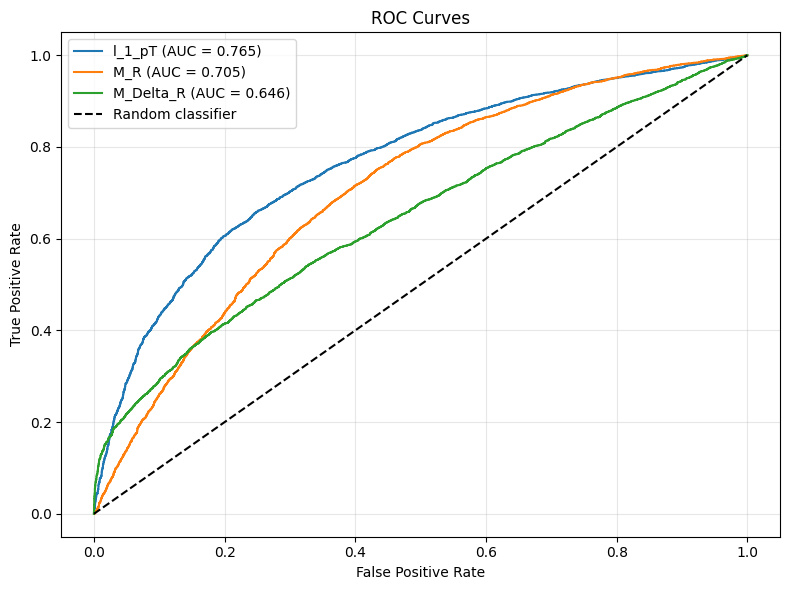

In [81]:
top_features = ["l_1_pT", "M_R", "M_Delta_R"]

plot_roc_curves(df_sig, df_bkg, top_features, n_samples=5000)

In [85]:
def plot_roc_after_cuts(df_sig, df_bkg, cuts, features, n_samples=5000):
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc

    sig = df_sig.iloc[:n_samples].copy()
    bkg = df_bkg.iloc[:n_samples].copy()

    stages = [("No cuts", sig, bkg)]

    for feature, threshold in cuts:
        sig = sig[sig[feature] > threshold]
        bkg = bkg[bkg[feature] > threshold]
        stages.append((f"After {feature} > {threshold}", sig, bkg))

    fig, axes = plt.subplots(1, len(stages), figsize=(5 * len(stages), 4))

    for ax, (stage, signal_df, background_df) in zip(axes, stages):
        for feature in features:
            signal = signal_df[feature].to_numpy()
            background = background_df[feature].to_numpy()

            if len(signal) == 0 or len(background) == 0:
                continue

            y_true = np.concatenate([
                np.ones(len(signal)),
                np.zeros(len(background))
            ])
            scores = np.concatenate([signal, background])

            fpr, tpr, _ = roc_curve(y_true, scores)
            roc_auc = auc(fpr, tpr)

            if roc_auc < 0.5:
                fpr, tpr, _ = roc_curve(y_true, -scores)
                roc_auc = auc(fpr, tpr)

            ax.plot(fpr, tpr, label=f"{feature} (AUC={roc_auc:.3f})")

        ax.plot([0, 1], [0, 1], "k--")
        ax.set_title(stage)
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Used LLM for this one to help write this one and debug the ROC function

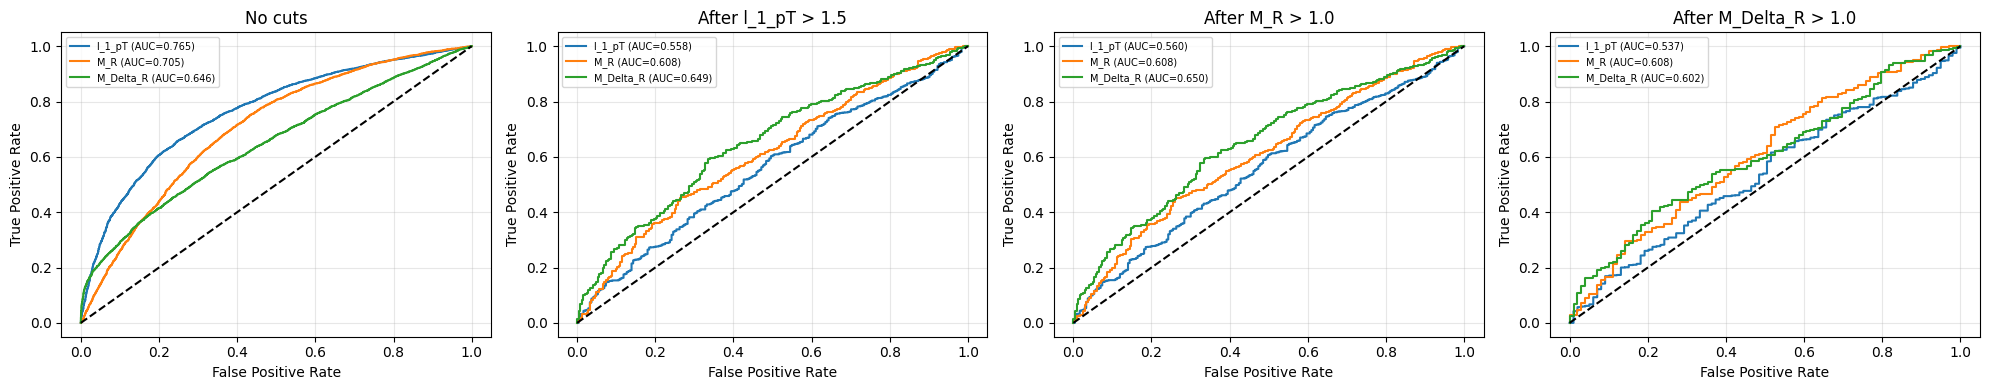

In [86]:
cuts = [
    ("l_1_pT", 1.5),
    ("M_R", 1.0),
    ("M_Delta_R", 1.0)
]

top_features = ["l_1_pT", "M_R", "M_Delta_R"]

plot_roc_after_cuts(
    df_sig, df_bkg, cuts, top_features, n_samples=5000
)

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$.

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5?

In [87]:
import numpy as np


features = list(low_features) + list(high_features)

X_signal = df_sig[features].to_numpy()
X_background = df_bkg[features].to_numpy()

m1 = np.mean(X_signal, axis=0)
m2 = np.mean(X_background, axis=0)

mean_difference = m2 - m1
S_B = np.outer(mean_difference, mean_difference)

S_W = np.zeros((len(features), len(features)))

for X, mean in [(X_signal, m1), (X_background, m2)]:
    deviations = X - mean
    S_W += deviations.T @ deviations

print("Between-class matrix S_B:")
print(S_B)

print("\nWithin-class matrix S_W:")
print(S_W)

print("\nS_B shape:", S_B.shape)
print("S_W shape:", S_W.shape)

Between-class matrix S_B:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   5.53227373e-02  8.54657090e-02  2.66557653e-01  7.37824064e-02
   1.84116478e-01  1.82331687e-01  5.66281031e-02  1.74241790e-01
   2.71136238e-01  1.54056891e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   8.81648006e-05  1.36201995e-04  4.24798257e-04  1.17582959e-04
   2.93416294e-04  2.90571971e-04  9.02450903e-05  2.77679548e-04
   4.32094896e-04  2.45511986e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   8.98064286e-05  1.38738075e-04  4.32707998e-04  1.19772353e-04
   2.98879704e-04  2.95982420e-04  9.19254533e-05  2.82849940e-04
   4.40140500e-04  2.50083417e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.391144

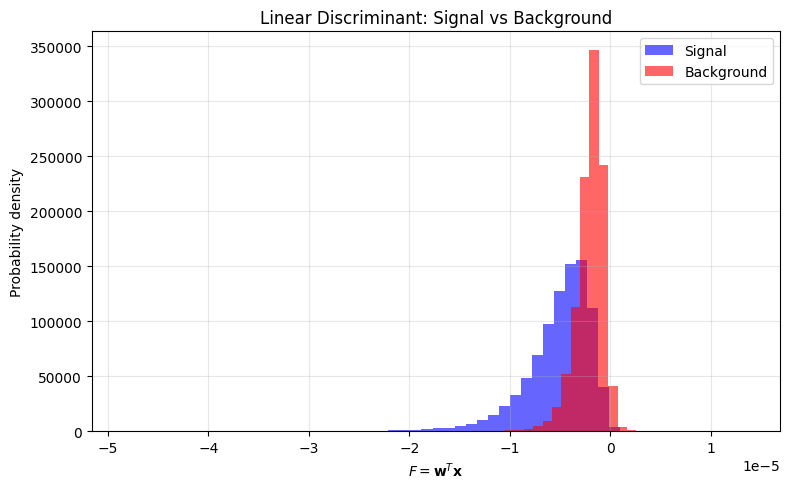

Linear coefficients w:
[-2.26832982e-06 -5.63688439e-09 -2.10423856e-09 -9.95582982e-07
 -3.48452234e-09 -2.70762588e-09 -1.65185357e-06 -2.74241844e-09
  2.11167032e-06 -2.64205675e-07 -1.48465692e-07  3.24040633e-07
 -1.69348122e-06  2.72149250e-07 -5.06860437e-06  1.81173242e-06
 -1.39723282e-07  7.50902836e-08]


In [88]:
import numpy as np
import matplotlib.pyplot as plt

mean_difference = m2 - m1
w = np.linalg.solve(S_W, mean_difference)

F_signal = X_signal @ w
F_background = X_background @ w

plt.figure(figsize=(8, 5))

plt.hist(F_signal, bins=50, density=True,
         alpha=0.6, label="Signal", color="blue")

plt.hist(F_background, bins=50, density=True,
         alpha=0.6, label="Background", color="red")

plt.xlabel(r"$F = \mathbf{w}^T\mathbf{x}$")
plt.ylabel("Probability density")
plt.title("Linear Discriminant: Signal vs Background")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Linear coefficients w:")
print(w)



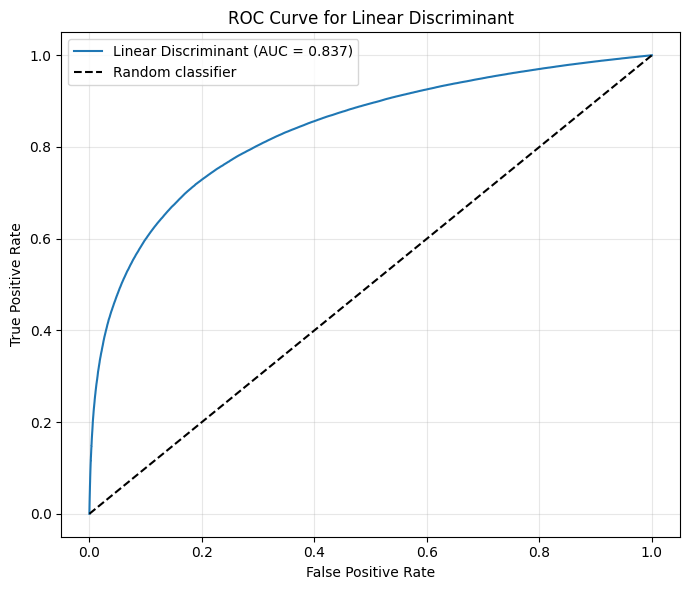

Area under the ROC curve: 0.8375


In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc


F_signal = np.asarray(X_signal @ w).ravel()
F_background = np.asarray(X_background @ w).ravel()


y_true = np.concatenate([
    np.ones(len(F_signal)),
    np.zeros(len(F_background))
])
scores = np.concatenate([F_signal, F_background])


fpr, tpr, thresholds = roc_curve(y_true, scores)
roc_auc = auc(fpr, tpr)


if roc_auc < 0.5:
    scores = -scores
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Linear Discriminant (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Linear Discriminant")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Area under the ROC curve:", round(roc_auc, 4))

# Had to use LLM for this one as my original code was not working the way I expected it to


In [92]:
import numpy as np
import pandas as pd
from IPython.display import display

F_signal = np.asarray(X_signal @ w).ravel()
F_background = np.asarray(X_background @ w).ravel()


scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]


thresholds = np.linspace(
    min(F_signal.min(), F_background.min()),
    max(F_signal.max(), F_background.max()),
    500
)

results = []

for NS, NB in scenarios:
    best_significance = 0
    best_threshold = None
    best_signal_efficiency = 0
    best_background_efficiency = 0

    for threshold in thresholds:

        eps_S = np.mean(F_signal > threshold)
        eps_B = np.mean(F_background > threshold)

        NS_prime = NS * eps_S
        NB_prime = NB * eps_B

        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(NS_prime + NB_prime)
        else:
            significance = 0

        if significance > best_significance:
            best_significance = significance
            best_threshold = threshold
            best_signal_efficiency = eps_S
            best_background_efficiency = eps_B

    results.append({"Maximum significance": best_significance})

display(pd.DataFrame(results).round(4))

,Maximum significance
0,0.9535
1,3.0151
2,9.5346
3,30.1510
